# House Prices

Explore the Ames housing data and compare Bayesian price models.


In [54]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib seaborn scipy pymc arviz scikit-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip


## Set up

Load the packages and point to the local data folder.


In [55]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Dataset folder.
path = Path("/Users/abdirahmanali/Fall 2026/Bayesian/Kaggle-Housing-Prediction-dataset/data")
required_files = ["train.csv", "test.csv", "data_description.txt", "sample_submission.csv"]
missing_files = [name for name in required_files if not (path / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing files in {path}: {', '.join(missing_files)}")

print("Data folder:", path)
print("Available files:", sorted(file.name for file in path.iterdir() if file.is_file()))


Data folder: /Users/abdirahmanali/Fall 2026/Bayesian/Kaggle-Housing-Prediction-dataset/data
Available files: ['absence_cleaning_audit.csv', 'absence_unresolved.csv', 'data_description.txt', 'model_handoff.csv', 'sample_submission.csv', 'test.csv', 'test_cleaned.csv', 'test_selected.csv', 'train.csv', 'train_cleaned.csv', 'train_selected.csv']


## Load the data

Read the local files and exclude home 1299 because of its unusual size and `Partial` sale condition. Keep `None` as the masonry category.


In [56]:
# Preserve the masonry-veneer category "None".
train_path = path / "train.csv"
test_path = path / "test.csv"

train_df = pd.read_csv(train_path, keep_default_na=False, na_values=["NA", ""])
test_df = pd.read_csv(test_path, keep_default_na=False, na_values=["NA", ""])

# Keep the original ID order for a consistent split.
source_ids = train_df['Id'].to_numpy().copy()
EXCLUDED_HOME_IDS = [1299]
train_df = train_df.loc[~train_df['Id'].isin(EXCLUDED_HOME_IDS)].copy()

print('Excluded home IDs:', EXCLUDED_HOME_IDS)
print(f"Loaded train.csv: {train_df.shape}")
display(train_df.head())
print(f"Loaded test.csv: {test_df.shape}")


Excluded home IDs: [1299]
Loaded train.csv: (1459, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Loaded test.csv: (1459, 80)


## Define the cleaning rules

Use the data dictionary and size/count fields to identify missing amenities.


In [57]:
# Recode confirmed absence categories.
# Confirm absence using size/count columns.
absence_rules = {
    'Alley': ('No alley access', None),
    'BsmtQual': ('No basement', 'TotalBsmtSF'),
    'BsmtCond': ('No basement', 'TotalBsmtSF'),
    'BsmtExposure': ('No basement', 'TotalBsmtSF'),
    'BsmtFinType1': ('No basement', 'TotalBsmtSF'),
    'BsmtFinType2': ('No basement', 'TotalBsmtSF'),
    'FireplaceQu': ('No fireplace', 'Fireplaces'),
    'GarageType': ('No garage', 'GarageCars'),
    'GarageFinish': ('No garage', 'GarageCars'),
    'GarageQual': ('No garage', 'GarageCars'),
    'GarageCond': ('No garage', 'GarageCars'),
    'PoolQC': ('No pool', 'PoolArea'),
    'Fence': ('No fence', None),
    'MiscFeature': ('No miscellaneous feature', 'MiscVal'),
}

def clean_absences(frame, dataset_name):
    cleaned = frame.copy()
    audit = []
    conflicts = []
    for column, (label, companion) in absence_rules.items():
        missing = cleaned[column].isna()
        if companion is None:
            confirmed_absent = missing
        else:
            confirmed_absent = missing & cleaned[companion].eq(0)
            if companion == 'GarageCars':
                confirmed_absent &= cleaned['GarageArea'].eq(0)
        cleaned.loc[confirmed_absent, column] = label
        unresolved = missing & ~confirmed_absent
        audit.append({
            'dataset': dataset_name,
            'variable': column,
            'missing_before': int(missing.sum()),
            'recoded_as_absent': int(confirmed_absent.sum()),
            'still_missing': int(unresolved.sum()),
        })
        for _, row in cleaned.loc[unresolved].iterrows():
            conflicts.append({
                'dataset': dataset_name, 'Id': row['Id'],
                'variable': column, 'check_column': companion,
                'check_value': row[companion] if companion else None,
            })
    return cleaned, audit, conflicts


## Clean and save

Apply those rules to both datasets. Save cleaned copies and an audit of the entries that still need review.


In [58]:
# Keep raw copies for comparison.
train_raw_df = train_df.copy()
test_raw_df = test_df.copy()
train_df, train_audit, train_conflicts = clean_absences(train_raw_df, 'train')
test_df, test_audit, test_conflicts = clean_absences(test_raw_df, 'test')

absence_audit = pd.DataFrame(train_audit + test_audit)
unresolved_absences = pd.DataFrame(
    train_conflicts + test_conflicts,
    columns=['dataset', 'Id', 'variable', 'check_column', 'check_value']
)
display(absence_audit)
if not unresolved_absences.empty:
    print('Unresolved entries:')
    display(unresolved_absences)

# Export cleaned datasets and audits.
train_df.to_csv(path / 'train_cleaned.csv', index=False, na_rep='NA')
test_df.to_csv(path / 'test_cleaned.csv', index=False, na_rep='NA')
absence_audit.to_csv(path / 'absence_cleaning_audit.csv', index=False)
unresolved_absences.to_csv(path / 'absence_unresolved.csv', index=False)
print('Saved train_cleaned.csv, test_cleaned.csv, and cleaning audit files.')


,dataset,variable,missing_before,recoded_as_absent,still_missing
0,train,Alley,1368,1368,0
1,train,BsmtQual,37,37,0
2,train,BsmtCond,37,37,0
3,train,BsmtExposure,38,37,1
4,train,BsmtFinType1,37,37,0
5,train,BsmtFinType2,38,37,1
6,train,FireplaceQu,690,690,0
7,train,GarageType,81,81,0
8,train,GarageFinish,81,81,0
9,train,GarageQual,81,81,0


Unresolved entries:


,dataset,Id,variable,check_column,check_value
0,train,949,BsmtExposure,TotalBsmtSF,936.0
1,train,333,BsmtFinType2,TotalBsmtSF,3206.0
2,test,2121,BsmtQual,TotalBsmtSF,NaN
3,test,2218,BsmtQual,TotalBsmtSF,173.0
4,test,2219,BsmtQual,TotalBsmtSF,356.0
5,test,2041,BsmtCond,TotalBsmtSF,1426.0
6,test,2121,BsmtCond,TotalBsmtSF,NaN
7,test,2186,BsmtCond,TotalBsmtSF,1127.0
8,test,2525,BsmtCond,TotalBsmtSF,995.0
9,test,1488,BsmtExposure,TotalBsmtSF,1595.0


Saved train_cleaned.csv, test_cleaned.csv, and cleaning audit files.


## Check the basics

Check the column types, row counts, and price range before screening predictors.


In [59]:
# 1. Basic Information
print("Train Dataset Summary Info:")
train_df.info()

# 2. Summary statistics of the target variable
print("\nTarget Variable (SalePrice) Summary:")
print(train_df['SalePrice'].describe())

Train Dataset Summary Info:
<class 'pandas.DataFrame'>
Index: 1459 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1459 non-null   str    
 3   LotFrontage    1200 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   Alley          1459 non-null   str    
 7   LotShape       1459 non-null   str    
 8   LandContour    1459 non-null   str    
 9   Utilities      1459 non-null   str    
 10  LotConfig      1459 non-null   str    
 11  LandSlope      1459 non-null   str    
 12  Neighborhood   1459 non-null   str    
 13  Condition1     1459 non-null   str    
 14  Condition2     1459 non-null   str    
 15  BldgType       1459 non-null   str    
 16  HouseStyle     1459 non-null   str    
 17  OverallQual    1459 non-null   int64  
 

## Set the split and cutoffs

Keep the existing training and held-out groups for the remaining homes. Set the missingness and association cutoffs here.


In [60]:
# Screening thresholds.
MISSING_CUTOFF = 0.40
PEARSON_CUTOFF = 0.30
ETA_SQUARED_CUTOFF = 0.10
ORIGINAL_CANDIDATES = [
    'GrLivArea', 'OverallQual', 'YearBuilt',
    'LotArea', 'GarageCars', 'Neighborhood'
]

# Shuffle the original IDs, then select the included homes.
rng = np.random.default_rng(6810)
shuffled_ids = rng.permutation(source_ids)
n_holdout = int(np.ceil(0.20 * len(source_ids)))
included_ids = set(train_df['Id'])
holdout_ids = [home for home in shuffled_ids[:n_holdout] if home in included_ids]
training_ids = [home for home in shuffled_ids[n_holdout:] if home in included_ids]
indexed_data = train_df.set_index('Id', drop=False)
holdout_df = indexed_data.loc[holdout_ids].reset_index(drop=True)
screening_df = indexed_data.loc[training_ids].reset_index(drop=True)
assert screening_df['SalePrice'].gt(0).all()
log_price = np.log(screening_df['SalePrice'])
print(f'Screening: {len(screening_df)} homes; held out: {len(holdout_df)} homes.')
predictor_columns = [c for c in screening_df.columns if c not in ['Id', 'SalePrice']]


Screening: 1168 homes; held out: 291 homes.


## Compare raw and log price

Put both distributions side by side and compare skewness to see how the log transformation changes the shape.


In [ ]:
price_summary = pd.DataFrame({
    'SalePrice': screening_df['SalePrice'].describe(),
    'log(SalePrice)': log_price.describe()
})
price_summary.loc['skewness'] = [screening_df['SalePrice'].skew(), log_price.skew()]
display(price_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(screening_df['SalePrice'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set(title='Raw sale price', xlabel='SalePrice ($)')
sns.histplot(log_price, bins=40, kde=True, ax=axes[1], color='teal')
axes[1].set(title='Natural log of sale price', xlabel='log(SalePrice)')
plt.tight_layout()
plt.show()


## Check remaining missing values

Count missing values after cleaning. Flag columns above the 40% cutoff.


In [62]:
# Unknown values after accounting for documented absences.
missingness_table = pd.DataFrame({
    'missing_n': screening_df[predictor_columns].isna().sum(),
    'missing_pct': 100 * screening_df[predictor_columns].isna().mean()
})
missingness_table['excluded_by_cutoff'] = missingness_table['missing_pct'] > 100 * MISSING_CUTOFF
display(missingness_table.sort_values('missing_pct', ascending=False).round(2))
print('Predictors excluded by missingness:', missingness_table.index[missingness_table['excluded_by_cutoff']].tolist())


,missing_n,missing_pct,excluded_by_cutoff
LotFrontage,209,17.89,False
GarageYrBlt,69,5.91,False
MasVnrType,7,0.60,False
MasVnrArea,7,0.60,False
Electrical,1,0.09,False
...,...,...,...
ExterCond,0,0.00,False
ExterQual,0,0.00,False
Exterior2nd,0,0.00,False
Exterior1st,0,0.00,False


Predictors excluded by missingness: []


## Score all predictors

Calculate Pearson and Spearman correlations for numeric predictors, and eta-squared for categorical predictors.


In [63]:
# Categorical code columns.
categorical_codes = {'MSSubClass', 'MoSold'}
predictor_columns = [c for c in screening_df.columns if c not in ['Id', 'SalePrice']]
assert len(predictor_columns) == 79

def eta_squared(groups, response):
    """Fraction of response variation between category means."""
    table = pd.DataFrame({'group': groups, 'response': response}).dropna()
    grouped = table.groupby('group', observed=True)['response']
    total = ((table['response'] - table['response'].mean()) ** 2).sum()
    counts = grouped.size()
    if len(counts) < 2 or total == 0:
        return np.nan, len(counts), int(counts.min()) if len(counts) else 0
    between = (counts * (grouped.mean() - table['response'].mean()) ** 2).sum()
    return float(between / total), len(counts), int(counts.min())

records = []
for variable in predictor_columns:
    values = screening_df[variable]
    numeric = pd.api.types.is_numeric_dtype(values) and variable not in categorical_codes
    record = {
        'variable': variable,
        'source': 'Original six' if variable in ORIGINAL_CANDIDATES else 'Other predictors',
        'type': 'Numeric / ordered' if numeric else 'Categorical',
        'missing_n': int(values.isna().sum()),
        'missing_pct': 100 * values.isna().mean(),
        'n_used': int(values.notna().sum()),
        'pearson_price': np.nan, 'pearson_log_price': np.nan,
        'spearman': np.nan, 'eta2_price': np.nan, 'eta2_log_price': np.nan,
        'levels': np.nan, 'smallest_group': np.nan,
        'passes_screen': False, 'note': ''
    }
    if values.isna().mean() > MISSING_CUTOFF:
        record['note'] = 'Excluded by missingness cutoff'
    elif values.nunique(dropna=True) < 2:
        record['note'] = 'No variation'
    elif numeric:
        record['pearson_price'] = values.corr(screening_df['SalePrice'])
        record['pearson_log_price'] = values.corr(log_price)
        record['spearman'] = values.corr(log_price, method='spearman')
        record['passes_screen'] = bool(abs(record['pearson_log_price']) >= PEARSON_CUTOFF)
        if not record['passes_screen'] and abs(record['spearman']) >= PEARSON_CUTOFF:
            record['note'] = 'Spearman magnitude exceeds the screening threshold'
    else:
        record['eta2_price'], _, _ = eta_squared(values, screening_df['SalePrice'])
        record['eta2_log_price'], record['levels'], record['smallest_group'] = eta_squared(values, log_price)
        record['passes_screen'] = bool(record['eta2_log_price'] >= ETA_SQUARED_CUTOFF)
        if record['smallest_group'] < 5:
            record['note'] = 'Smallest category contains fewer than 5 homes'
    records.append(record)


## Compare our candidates with the rest

Show the six proposed predictors and the other 73 predictors in separate tables. Count how many pass the cutoffs.


In [64]:
screening_results = pd.DataFrame(records)
columns_to_show = [
    'variable', 'type', 'missing_pct', 'n_used',
    'pearson_price', 'pearson_log_price', 'spearman',
    'eta2_price', 'eta2_log_price', 'passes_screen', 'note'
]
original_results = screening_results.set_index('variable').loc[ORIGINAL_CANDIDATES].reset_index()
other_results = screening_results[screening_results['source'].eq('Other predictors')].copy()
# Rank predictors within each type.
other_results['within_type_score'] = other_results['pearson_log_price'].abs().fillna(other_results['eta2_log_price'])
other_results = other_results.sort_values(['type', 'within_type_score'], ascending=[True, False])

print('ORIGINAL SIX CANDIDATES')
display(original_results[columns_to_show].round(3))
print('ALL OTHER PREDICTORS (ranked within type)')
display(other_results[columns_to_show].round(3))
screening_counts = screening_results.groupby('source').agg(
    total=('variable', 'size'), passed=('passes_screen', 'sum')
)
display(screening_counts)


ORIGINAL SIX CANDIDATES


,variable,type,missing_pct,n_used,pearson_price,pearson_log_price,spearman,eta2_price,eta2_log_price,passes_screen,note
0,GrLivArea,Numeric / ordered,0.0,1168,0.730,0.721,0.738,NaN,NaN,True,
1,OverallQual,Numeric / ordered,0.0,1168,0.795,0.825,0.814,NaN,NaN,True,
2,YearBuilt,Numeric / ordered,0.0,1168,0.511,0.580,0.652,NaN,NaN,True,
3,LotArea,Numeric / ordered,0.0,1168,0.275,0.266,0.466,NaN,NaN,False,Spearman magnitude exceeds the screening thres...
4,GarageCars,Numeric / ordered,0.0,1168,0.640,0.684,0.694,NaN,NaN,True,
5,Neighborhood,Categorical,0.0,1168,NaN,NaN,NaN,0.528,0.555,True,Smallest category contains fewer than 5 homes


ALL OTHER PREDICTORS (ranked within type)


,variable,type,missing_pct,n_used,pearson_price,pearson_log_price,spearman,eta2_price,eta2_log_price,passes_screen,note
26,ExterQual,Categorical,0.0,1168,NaN,NaN,NaN,0.473,0.456,True,
52,KitchenQual,Categorical,0.0,1168,NaN,NaN,NaN,0.461,0.450,True,
29,BsmtQual,Categorical,0.0,1168,NaN,NaN,NaN,0.467,0.446,True,
59,GarageFinish,Categorical,0.0,1168,NaN,NaN,NaN,0.290,0.370,True,
0,MSSubClass,Categorical,0.0,1168,NaN,NaN,NaN,0.245,0.338,True,Smallest category contains fewer than 5 homes
...,...,...,...,...,...,...,...,...,...,...,...
44,LowQualFinSF,Numeric / ordered,0.0,1168,-0.020,-0.036,-0.075,NaN,NaN,False,
74,MiscVal,Numeric / ordered,0.0,1168,-0.033,-0.035,-0.081,NaN,NaN,False,
47,BsmtHalfBath,Numeric / ordered,0.0,1168,-0.028,-0.016,-0.025,NaN,NaN,False,
17,OverallCond,Numeric / ordered,0.0,1168,-0.059,-0.013,-0.111,NaN,NaN,False,


,total,passed
source,,
Original six,6,5
Other predictors,73,36


## Rank the candidates

Plot the strongest numeric and categorical associations so the new candidates are easy to spot.


In [ ]:
# Show the strongest associations separately for numeric and categorical predictors.
numeric_results = screening_results[screening_results['type'].eq('Numeric / ordered')].copy()
numeric_results['abs_pearson_log'] = numeric_results['pearson_log_price'].abs()
numeric_top = numeric_results.nlargest(15, 'abs_pearson_log').sort_values('abs_pearson_log')
categorical_top = screening_results[screening_results['type'].eq('Categorical')].nlargest(15, 'eta2_log_price').sort_values('eta2_log_price')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(numeric_top['variable'], numeric_top['abs_pearson_log'], color='steelblue')
axes[0].axvline(PEARSON_CUTOFF, color='darkred', linestyle='--')
axes[0].set(title='Numeric predictors: top 15', xlabel='Absolute Pearson correlation with log price')
axes[1].barh(categorical_top['variable'], categorical_top['eta2_log_price'], color='teal')
axes[1].axvline(ETA_SQUARED_CUTOFF, color='darkred', linestyle='--')
axes[1].set(title='Categorical predictors: top 15', xlabel='Eta-squared with log price')
plt.tight_layout()
plt.show()


## Look at the original numeric candidates

Compare their relationships with raw and log price. Look for curves and unusually large homes.


In [ ]:
# Compare raw and log-price relationships for the original numeric candidates.
numeric_candidates = [v for v in ORIGINAL_CANDIDATES if v != 'Neighborhood']
fig, axes = plt.subplots(len(numeric_candidates), 2, figsize=(12, 16))
for row, variable in enumerate(numeric_candidates):
    for col, (response, label) in enumerate([
        (screening_df['SalePrice'], 'SalePrice ($)'), (log_price, 'log(SalePrice)')
    ]):
        sns.regplot(x=screening_df[variable], y=response, ci=None,
                    scatter_kws={'alpha': 0.25, 's': 12},
                    line_kws={'color': 'darkred'}, ax=axes[row, col])
        axes[row, col].set(xlabel=variable, ylabel=label)
plt.tight_layout()
plt.show()


## Check neighborhoods and overlap

Show neighborhood prices and sample sizes, then check which numeric candidates carry similar information.


In [ ]:
# Neighborhood is categorical: display distributions and group sizes.
neighborhood_data = screening_df[['Neighborhood', 'SalePrice']].copy()
neighborhood_data['LogSalePrice'] = log_price
neighborhood_summary = neighborhood_data.groupby('Neighborhood').agg(
    n=('SalePrice', 'size'), median_price=('SalePrice', 'median'),
    median_log_price=('LogSalePrice', 'median')
).sort_values('median_price')
display(neighborhood_summary)
plt.figure(figsize=(13, 5))
sns.boxplot(data=neighborhood_data, x='Neighborhood', y='LogSalePrice',
            order=neighborhood_summary.index)
plt.xticks(rotation=90)
plt.title('Log sale price by neighborhood')
plt.tight_layout()
plt.show()

# Check overlapping information among numeric variables passing the screen.
selected_numeric = numeric_results.loc[numeric_results['passes_screen'], 'variable'].tolist()
if len(selected_numeric) > 1:
    plt.figure(figsize=(12, 10))
    sns.heatmap(screening_df[selected_numeric].corr(), cmap='coolwarm', vmin=-1, vmax=1)
    plt.title('Correlation among shortlisted numeric predictors')
    plt.tight_layout()
    plt.show()


## Check lot area and overlapping predictors

Compare raw and log lot area. Check the pairs used to choose living area, garage capacity, and basement area.


In [68]:
import pymc as pm
import arviz as az

results_path = path.parent / 'analysis_results'
results_path.mkdir(exist_ok=True)

transformation_check = pd.DataFrame({
    'predictor': ['LotArea', 'log(LotArea)'],
    'pearson_log_price': [
        screening_df['LotArea'].corr(log_price),
        np.log(screening_df['LotArea']).corr(log_price)
    ]
})
display(transformation_check.round(3))

overlap_pairs = [('GarageCars', 'GarageArea'), ('GrLivArea', 'TotRmsAbvGrd'),
                 ('TotalBsmtSF', '1stFlrSF')]
overlap_table = pd.DataFrame([
    {'predictor_1': first, 'predictor_2': second,
     'correlation': screening_df[first].corr(screening_df[second])}
    for first, second in overlap_pairs
])
display(overlap_table.round(3))


,predictor,pearson_log_price
0,LotArea,0.266
1,log(LotArea),0.406


,predictor_1,predictor_2,correlation
0,GarageCars,GarageArea,0.888
1,GrLivArea,TotRmsAbvGrd,0.832
2,TotalBsmtSF,1stFlrSF,0.821


## Prepare the model inputs

Score kitchen quality from 1 to 5. Fill numeric gaps and standardize inputs using the training sample, then apply the same settings to the held-out homes.


In [69]:
kitchen_scores = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
baseline_features = ['GrLivArea', 'OverallQual', 'YearBuilt']
expanded_features = baseline_features + [
    'LogLotArea', 'GarageCars', 'TotalBsmtSF', 'KitchenQualityScore'
]

def model_features(frame):
    features = frame[baseline_features + ['GarageCars', 'TotalBsmtSF']].astype(float).copy()
    if not frame['LotArea'].dropna().gt(0).all():
        raise ValueError('LotArea must be positive for the log transformation.')
    features['LogLotArea'] = np.log(frame['LotArea'])
    known_ratings = frame['KitchenQual'].dropna()
    if not known_ratings.isin(kitchen_scores).all():
        raise ValueError('Unexpected KitchenQual category.')
    features['KitchenQualityScore'] = frame['KitchenQual'].map(kitchen_scores).astype(float)
    return features[expanded_features]

# Imputation and standardization use the training sample.
features_train = model_features(screening_df)
features_holdout = model_features(holdout_df)
training_medians = features_train.median()
features_train = features_train.fillna(training_medians)
features_holdout = features_holdout.fillna(training_medians)
feature_means = features_train.mean()
feature_scales = features_train.std(ddof=0)
if feature_scales.le(0).any() or features_train.isna().any().any():
    raise ValueError('Check constant or entirely missing model inputs.')
X_train = (features_train - feature_means) / feature_scales
X_holdout = (features_holdout - feature_means) / feature_scales
y_train = np.log(screening_df['SalePrice'].to_numpy(dtype=float))
y_holdout = holdout_df['SalePrice'].to_numpy(dtype=float)

neighborhood_names = sorted(screening_df['Neighborhood'].unique())
neighborhood_index = {name: i for i, name in enumerate(neighborhood_names)}
train_neighborhood = screening_df['Neighborhood'].map(neighborhood_index).to_numpy(dtype=int)
holdout_neighborhood = holdout_df['Neighborhood'].map(neighborhood_index).fillna(-1).to_numpy(dtype=int)

preprocessing_table = pd.DataFrame({
    'imputation_median': training_medians,
    'training_mean': feature_means, 'training_sd': feature_scales
})
display(preprocessing_table.round(3))
preprocessing_table.to_csv(results_path / 'preprocessing.csv')
split_table = pd.concat([
    screening_df[['Id']].assign(sample='training'),
    holdout_df[['Id']].assign(sample='holdout')
])
split_table.to_csv(results_path / 'data_split.csv', index=False)
print(f'Training homes: {len(y_train)}; held-out homes: {len(y_holdout)}')
print(f'Neighborhoods in training sample: {len(neighborhood_names)}')


,imputation_median,training_mean,training_sd
GrLivArea,1457.000,1512.808,528.906
OverallQual,6.000,6.099,1.403
YearBuilt,1974.000,1971.634,30.122
LogLotArea,9.163,9.111,0.514
GarageCars,2.000,1.780,0.755
TotalBsmtSF,997.000,1064.921,422.223
KitchenQualityScore,3.000,3.521,0.673


Training homes: 1168; held-out homes: 291
Neighborhoods in training sample: 25


## Define the Bayesian models

Use log price with standardized predictors. Add a shared neighborhood model for partial pooling.


In [70]:
CHAINS = 4
DRAWS = 1000
TUNE = 1500
TARGET_ACCEPT = 0.95
SEED = 6810

def fit_price_model(feature_names, hierarchical=False, train_features=None):
    inputs = X_train if train_features is None else train_features
    coords = {'feature': feature_names, 'home': screening_df['Id'].to_numpy()}
    if hierarchical:
        coords['neighborhood'] = neighborhood_names
    with pm.Model(coords=coords) as model:
        alpha = pm.Normal('alpha', mu=float(y_train.mean()), sigma=0.7)
        beta = pm.Normal('beta', mu=0.0, sigma=0.5, dims='feature')
        sigma = pm.HalfNormal('sigma', sigma=0.5)
        mu = alpha + pm.math.dot(inputs[feature_names].to_numpy(), beta)
        if hierarchical:
            neighborhood_sd = pm.HalfNormal('neighborhood_sd', sigma=0.3)
            neighborhood_z = pm.ZeroSumNormal('neighborhood_z', sigma=1.0,
                                              dims='neighborhood')
            effects = pm.Deterministic('neighborhood_effect',
                                       neighborhood_z * neighborhood_sd,
                                       dims='neighborhood')
            mu = mu + effects[train_neighborhood]
        pm.Normal('log_price_obs', mu=mu, sigma=sigma, observed=y_train, dims='home')
        prior = pm.sample_prior_predictive(draws=200, random_seed=SEED)
        posterior = pm.sample(
            draws=DRAWS, tune=TUNE, chains=CHAINS, cores=2,
            target_accept=TARGET_ACCEPT, random_seed=SEED,
            blas_cores=1, progressbar=True
        )
    return model, posterior, prior


## Fit the baseline and expanded models

Start with living area, quality, and year built. Fit the expanded model with the extra property features and neighborhood effects using the same four-chain settings.


In [71]:
baseline_model, baseline_fit, baseline_prior = fit_price_model(baseline_features)
expanded_model, expanded_fit, expanded_prior = fit_price_model(expanded_features, hierarchical=True)

fits = {'Baseline': baseline_fit, 'Expanded': expanded_fit}
for name, fitted in fits.items():
    fitted.posterior.to_netcdf(results_path / f'{name.lower()}_posterior.nc', engine='scipy')
    fitted.sample_stats.to_netcdf(results_path / f'{name.lower()}_sample_stats.nc', engine='scipy')


Sampling: [alpha, beta, log_price_obs, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [alpha, beta, sigma]


/opt/homebrew/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 2 seconds.
Sampling: [alpha, beta, log_price_obs, neighborhood_sd, neighborhood_z, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [alpha, beta, sigma, neighborhood_sd, neighborhood_z]


/opt/homebrew/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 6 seconds.


## Check the sampling

Check R-hat, effective sample sizes, and divergences to see whether the chains sampled consistently.


In [72]:
def sampling_diagnostics(name, fitted):
    variables = ['alpha', 'beta', 'sigma']
    if 'neighborhood_sd' in fitted.posterior:
        variables += ['neighborhood_sd', 'neighborhood_z']
    filename = name.lower().replace(' ', '_')
    az.summary(fitted, var_names=variables, hdi_prob=0.90, round_to=4).to_csv(
        results_path / f'{filename}_parameter_summary.csv'
    )
    max_rhat = float(az.rhat(fitted, var_names=variables).to_array().max())
    min_bulk_ess = float(az.ess(fitted, var_names=variables, method='bulk').to_array().min())
    min_tail_ess = float(az.ess(fitted, var_names=variables, method='tail').to_array().min())
    divergences = int(fitted.sample_stats['diverging'].sum())
    return {
        'model': name, 'max_rhat': max_rhat, 'min_bulk_ess': min_bulk_ess,
        'min_tail_ess': min_tail_ess, 'divergences': divergences,
        'sampling_check': max_rhat < 1.01 and min_bulk_ess >= 400
                          and min_tail_ess >= 400 and divergences == 0
    }

diagnostics = pd.DataFrame([
    sampling_diagnostics(name, fitted) for name, fitted in fits.items()
])
display(diagnostics.round(3))
diagnostics.to_csv(results_path / 'sampling_diagnostics.csv', index=False)


,model,max_rhat,min_bulk_ess,min_tail_ess,divergences,sampling_check
0,Baseline,1.002,2209.511,2373.522,0,True
1,Expanded,1.004,987.585,1596.392,0,True


## Generate price predictions

Draw predicted prices from the fitted models, including residual variation, so we can calculate prediction intervals.


In [73]:
def predictive_draws(fitted, feature_names, frame_features, frame, seed):
    posterior = fitted.posterior.stack(sample=('chain', 'draw'))
    alpha = posterior['alpha'].transpose('sample').to_numpy()
    beta = posterior['beta'].transpose('sample', 'feature').to_numpy()
    sigma = posterior['sigma'].transpose('sample').to_numpy()
    mu = alpha[:, None] + beta @ frame_features[feature_names].to_numpy().T
    generator = np.random.default_rng(seed)
    if 'neighborhood_effect' in posterior:
        effects = posterior['neighborhood_effect'].transpose('sample', 'neighborhood').to_numpy()
        indices = frame['Neighborhood'].map(neighborhood_index).fillna(-1).to_numpy(dtype=int)
        known = indices >= 0
        mu[:, known] += effects[:, indices[known]]
        for neighborhood in frame.loc[~known, 'Neighborhood'].unique():
            same_group = frame['Neighborhood'].eq(neighborhood).to_numpy()
            group_sd = posterior['neighborhood_sd'].transpose('sample').to_numpy()
            new_effect = generator.normal(0, group_sd)
            mu[:, same_group] += new_effect[:, None]
    log_predictions = generator.normal(mu, sigma[:, None])
    price_predictions = np.exp(log_predictions)
    expected_price = np.exp(mu + 0.5 * sigma[:, None] ** 2).mean(axis=0)
    return mu, log_predictions, price_predictions, expected_price


## Compare held-out scores

Predict the same 291 held-out homes with both models. Compare price errors, interval coverage, and interval width.


In [74]:
def prediction_metrics(table):
    actual = table['actual_price'].to_numpy()
    predicted = table['predicted_mean'].to_numpy()
    return {
        'n_homes': len(table),
        'RMSE_dollars': np.sqrt(np.mean((actual - predicted) ** 2)),
        'MAE_dollars': np.mean(np.abs(actual - predicted)),
        'log_RMSE': np.sqrt(np.mean((np.log(actual) - np.log(predicted)) ** 2)),
        'coverage_90_pct': 100 * np.mean(
            (actual >= table['lower_90']) & (actual <= table['upper_90'])
        ),
        'mean_interval_width_dollars': (table['upper_90'] - table['lower_90']).mean()
    }

def evaluate_model(name, fitted, feature_names, held_features, seed):
    mu, log_draws, price_draws, mean_price = predictive_draws(
        fitted, feature_names, held_features, holdout_df, seed
    )
    lower, median, upper = np.quantile(price_draws, [0.05, 0.50, 0.95], axis=0)
    table = pd.DataFrame({
        'Id': holdout_df['Id'].to_numpy(), 'actual_price': y_holdout,
        'predicted_mean': mean_price, 'predicted_median': median,
        'lower_90': lower, 'upper_90': upper
    })
    table.to_csv(results_path / f'{name.lower().replace(" ", "_")}_holdout_predictions.csv', index=False)
    return {'table': table, 'mu': mu, 'log_draws': log_draws}

predictions = {}
for name, fitted, feature_names, seed in [
    ('Baseline', baseline_fit, baseline_features, SEED + 1),
    ('Expanded', expanded_fit, expanded_features, SEED + 2)
]:
    predictions[name] = evaluate_model(name, fitted, feature_names, X_holdout, seed)

comparison = pd.DataFrame([
    {'model': name, **prediction_metrics(output['table'])}
    for name, output in predictions.items()
]).set_index('model')
display(comparison.round(3))
comparison.to_csv(results_path / 'model_comparison.csv')


,n_homes,RMSE_dollars,MAE_dollars,log_RMSE,coverage_90_pct,mean_interval_width_dollars
model,,,,,,
Baseline,291,28074.861,20629.585,0.161,94.158,107489.832
Expanded,291,21451.351,16106.038,0.126,95.189,85575.043


## Check replicated training prices

Compare the mean and spread of replicated log prices with the observed training prices.


In [75]:
# Posterior predictive checks on the training sample.
training_log_predictions = {}
for name, fitted, feature_names, seed in [
    ('Baseline', baseline_fit, baseline_features, SEED + 3),
    ('Expanded', expanded_fit, expanded_features, SEED + 4)
]:
    _, log_draws, _, _ = predictive_draws(fitted, feature_names, X_train, screening_df, seed)
    training_log_predictions[name] = log_draws
    draw_statistics = pd.DataFrame({
        'mean_log_price': log_draws.mean(axis=1),
        'sd_log_price': log_draws.std(axis=1),
    }).quantile([0.05, 0.50, 0.95])
    print(name + ': replicated training-data statistics')
    display(draw_statistics.round(3))
print('Observed mean and SD of log price:', round(y_train.mean(), 3), round(y_train.std(), 3))


Baseline: replicated training-data statistics


,mean_log_price,sd_log_price
0.05,12.013,0.397
0.50,12.025,0.409
0.95,12.038,0.421


Expanded: replicated training-data statistics


,mean_log_price,sd_log_price
0.05,12.015,0.400
0.50,12.025,0.410
0.95,12.035,0.419


Observed mean and SD of log price: 12.025 0.409


## Look at the model checks

Plot prior predictions, sampling traces, and posterior predictions alongside the observed prices.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, prior in zip(axes, ['Baseline', 'Expanded'], [baseline_prior, expanded_prior]):
    prior_values = prior.prior_predictive['log_price_obs'].to_numpy().ravel()
    ax.hist(prior_values, bins=80, density=True, alpha=0.45, label='Prior predictions')
    ax.hist(y_train, bins=40, density=True, alpha=0.65, label='Observed')
    ax.set(title=name + ': prior predictive distribution', xlabel='log(SalePrice)', ylabel='Density')
    ax.legend()
plt.tight_layout()
plt.savefig(results_path / 'prior_predictive.png', dpi=140)
plt.show()

for name, fitted in fits.items():
    variables = ['alpha', 'sigma'] + (['neighborhood_sd'] if name == 'Expanded' else [])
    az.plot_trace(fitted, var_names=variables)
    plt.tight_layout()
    plt.savefig(results_path / f'{name.lower()}_trace.png', dpi=140)
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ['Baseline', 'Expanded']):
    ax.hist(y_train, bins=40, density=True, alpha=0.65, label='Observed')
    draws = training_log_predictions[name]
    for index in np.linspace(0, len(draws) - 1, 30, dtype=int):
        sns.kdeplot(draws[index], ax=ax, color='teal', alpha=0.10, linewidth=0.8)
    ax.set(title=name + ': posterior predictive check', xlabel='log(SalePrice)', ylabel='Density')
    ax.legend()
plt.tight_layout()
plt.savefig(results_path / 'posterior_predictive.png', dpi=140)
plt.show()


## Look at the held-out predictions

Plot predicted prices, 90% prediction intervals, and log residuals to see where the models miss.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['Baseline', 'Expanded']):
    table = predictions[name]['table']
    ax.scatter(table['actual_price'], table['predicted_mean'], alpha=0.5, s=18)
    limits = [min(table['actual_price'].min(), table['predicted_mean'].min()),
              max(table['actual_price'].max(), table['predicted_mean'].max())]
    ax.plot(limits, limits, '--', color='darkred')
    ax.set(title=name + ': held-out predictions', xlabel='Actual price ($)', ylabel='Predicted mean ($)')
plt.tight_layout()
plt.savefig(results_path / 'holdout_predictions.png', dpi=140)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ['Baseline', 'Expanded']):
    table = predictions[name]['table'].sort_values('actual_price')
    selected = table.iloc[np.linspace(0, len(table) - 1, 40, dtype=int)]
    x = np.arange(len(selected))
    ax.vlines(x, selected['lower_90'], selected['upper_90'], color='steelblue', alpha=0.7)
    ax.scatter(x, selected['predicted_mean'], color='steelblue', s=18, label='Predicted mean')
    ax.scatter(x, selected['actual_price'], color='darkred', s=18, label='Actual price')
    ax.set(title=name + ': 90% prediction intervals', xlabel='40 held-out homes, ordered by actual price', ylabel='Price ($)')
    ax.legend()
plt.tight_layout()
plt.savefig(results_path / 'prediction_intervals.png', dpi=140)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['Baseline', 'Expanded']):
    mu = predictions[name]['mu'].mean(axis=0)
    residual = np.log(y_holdout) - mu
    ax.scatter(mu, residual, alpha=0.45, s=18)
    ax.axhline(0, color='darkred', linestyle='--')
    ax.set(title=name + ': held-out log residuals', xlabel='Predicted log price', ylabel='Observed minus predicted log price')
plt.tight_layout()
plt.savefig(results_path / 'holdout_residuals.png', dpi=140)
plt.show()


## Look at neighborhood estimates

Plot the neighborhood price effects and their 90% credible intervals, with each neighborhood’s training count.


In [ ]:
# Neighborhood effects relative to the shared intercept.
effect_samples = expanded_fit.posterior['neighborhood_effect'].stack(sample=('chain', 'draw')).transpose('sample', 'neighborhood').to_numpy()
effect_percent = 100 * np.expm1(effect_samples)
effect_lower, effect_median, effect_upper = np.quantile(effect_percent, [0.05, 0.50, 0.95], axis=0)
neighborhood_effects = pd.DataFrame({
    'Neighborhood': neighborhood_names,
    'n_training': screening_df['Neighborhood'].value_counts().reindex(neighborhood_names).to_numpy(),
    'median_effect_pct': effect_median,
    'lower_90_pct': effect_lower, 'upper_90_pct': effect_upper
}).sort_values('median_effect_pct')
display(neighborhood_effects.round(2))
neighborhood_effects.to_csv(results_path / 'neighborhood_effects.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 8))
positions = np.arange(len(neighborhood_effects))
ax.hlines(positions, neighborhood_effects['lower_90_pct'], neighborhood_effects['upper_90_pct'], color='teal')
ax.scatter(neighborhood_effects['median_effect_pct'], positions, color='teal', s=20)
ax.set_yticks(positions, [f'{row.Neighborhood} (n={row.n_training})' for row in neighborhood_effects.itertuples()])
ax.axvline(0, linestyle='--', color='darkred')
ax.set(title='Partially pooled neighborhood effects: 90% credible intervals', xlabel='Price difference relative to shared intercept (%)')
plt.tight_layout()
plt.savefig(results_path / 'neighborhood_effects.png', dpi=140)
plt.show()


## Try log-transformed living and basement area

Use log living area and log(1 + basement area) to soften the effect of very large properties. Keep the same other predictors and data split.


In [79]:
log_size_features = [
    'LogGrLivArea', 'OverallQual', 'YearBuilt', 'LogLotArea',
    'GarageCars', 'LogBasementArea', 'KitchenQualityScore'
]

def log_size_inputs(features):
    transformed = features.copy()
    if not transformed['GrLivArea'].gt(0).all() or not transformed['TotalBsmtSF'].ge(0).all():
        raise ValueError('Check living and basement areas before taking logs.')
    transformed['LogGrLivArea'] = np.log(transformed['GrLivArea'])
    transformed['LogBasementArea'] = np.log1p(transformed['TotalBsmtSF'])
    return transformed[log_size_features]

log_features_train = log_size_inputs(features_train)
log_features_holdout = log_size_inputs(features_holdout)
log_feature_means = log_features_train.mean()
log_feature_scales = log_features_train.std(ddof=0)
X_log_train = (log_features_train - log_feature_means) / log_feature_scales
X_log_holdout = (log_features_holdout - log_feature_means) / log_feature_scales

log_size_preprocessing = pd.DataFrame({
    'training_mean': log_feature_means, 'training_sd': log_feature_scales
})
display(log_size_preprocessing.round(3))
log_size_preprocessing.to_csv(results_path / 'log_size_preprocessing.csv')


,training_mean,training_sd
LogGrLivArea,7.264,0.341
OverallQual,6.099,1.403
YearBuilt,1971.634,30.122
LogLotArea,9.111,0.514
GarageCars,1.780,0.755
LogBasementArea,6.772,1.100
KitchenQualityScore,3.521,0.673


## Fit the log-size model

Fit the expanded model with the transformed sizes. Check its sampling and compare its held-out scores with the first two models.


In [80]:
log_size_model, log_size_fit, log_size_prior = fit_price_model(
    log_size_features, hierarchical=True, train_features=X_log_train
)
fits['Log sizes'] = log_size_fit
log_size_fit.posterior.to_netcdf(results_path / 'log_sizes_posterior.nc', engine='scipy')
log_size_fit.sample_stats.to_netcdf(results_path / 'log_sizes_sample_stats.nc', engine='scipy')

diagnostics = pd.DataFrame([
    sampling_diagnostics(name, fitted) for name, fitted in fits.items()
])
display(diagnostics.round(3))
diagnostics.to_csv(results_path / 'sampling_diagnostics.csv', index=False)

predictions['Log sizes'] = evaluate_model(
    'Log sizes', log_size_fit, log_size_features, X_log_holdout, SEED + 5
)
comparison = pd.DataFrame([
    {'model': name, **prediction_metrics(output['table'])}
    for name, output in predictions.items()
]).set_index('model')
display(comparison.round(3))
comparison.to_csv(results_path / 'model_comparison.csv')


Sampling: [alpha, beta, log_price_obs, neighborhood_sd, neighborhood_z, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [alpha, beta, sigma, neighborhood_sd, neighborhood_z]


/opt/homebrew/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 6 seconds.


,model,max_rhat,min_bulk_ess,min_tail_ess,divergences,sampling_check
0,Baseline,1.002,2209.511,2373.522,0,True
1,Expanded,1.004,987.585,1596.392,0,True
2,Log sizes,1.003,958.913,1823.299,0,True


,n_homes,RMSE_dollars,MAE_dollars,log_RMSE,coverage_90_pct,mean_interval_width_dollars
model,,,,,,
Baseline,291,28074.861,20629.585,0.161,94.158,107489.832
Expanded,291,21451.351,16106.038,0.126,95.189,85575.043
Log sizes,291,22326.410,16300.408,0.127,94.845,85890.950


## Check the log-size model

Look at the traces, predicted price distribution, and held-out residuals for the transformed model.


In [ ]:
az.plot_trace(log_size_fit, var_names=['alpha', 'sigma', 'neighborhood_sd'])
plt.tight_layout()
plt.savefig(results_path / 'log_sizes_trace.png', dpi=140)
plt.show()

_, log_size_training_draws, _, _ = predictive_draws(
    log_size_fit, log_size_features, X_log_train, screening_df, SEED + 6
)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
prior_values = log_size_prior.prior_predictive['log_price_obs'].to_numpy().ravel()
axes[0].hist(prior_values, bins=80, density=True, alpha=0.45, label='Prior predictions')
axes[0].hist(y_train, bins=40, density=True, alpha=0.65, label='Observed')
axes[0].set(title='Log sizes: prior predictions', xlabel='log(SalePrice)')
axes[0].legend()
axes[1].hist(log_size_training_draws.ravel(), bins=80, density=True, alpha=0.45, label='Posterior predictions')
axes[1].hist(y_train, bins=40, density=True, alpha=0.65, label='Observed')
axes[1].set(title='Log sizes: posterior predictions', xlabel='log(SalePrice)')
axes[1].legend()
predicted_log_price = predictions['Log sizes']['mu'].mean(axis=0)
axes[2].scatter(predicted_log_price, np.log(y_holdout) - predicted_log_price, alpha=0.45, s=18)
axes[2].axhline(0, color='darkred', linestyle='--')
axes[2].set(title='Log sizes: held-out residuals', xlabel='Predicted log price', ylabel='Observed minus predicted')
plt.tight_layout()
plt.savefig(results_path / 'log_size_checks.png', dpi=140)
plt.show()


## Compare the final results

Plot the log-size predictions and compare all three models on the remaining held-out homes. Show the log-size model’s prediction intervals.


In [ ]:
table = predictions['Log sizes']['table']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(table['actual_price'], table['predicted_mean'], alpha=0.5, s=18)
limits = [min(table['actual_price'].min(), table['predicted_mean'].min()),
          max(table['actual_price'].max(), table['predicted_mean'].max())]
axes[0].plot(limits, limits, '--', color='darkred')
axes[0].set(title='Log-size model: held-out predictions', xlabel='Actual price ($)', ylabel='Predicted mean ($)')
axes[1].bar(comparison.index, comparison['RMSE_dollars'], color=['steelblue', 'teal', 'darkorange'])
axes[1].set(title='Model comparison: 291 held-out homes', ylabel='Dollar RMSE')
plt.tight_layout()
plt.savefig(results_path / 'log_size_predictions.png', dpi=140)
plt.show()

ordered = table.sort_values('actual_price')
selected = ordered.iloc[np.linspace(0, len(ordered) - 1, 40, dtype=int)]
x = np.arange(len(selected))
fig, ax = plt.subplots(figsize=(10, 4))
ax.vlines(x, selected['lower_90'], selected['upper_90'], color='teal', alpha=0.7)
ax.scatter(x, selected['predicted_mean'], color='teal', s=18, label='Predicted mean')
ax.scatter(x, selected['actual_price'], color='darkred', s=18, label='Actual price')
ax.set(title='Log-size model: 90% prediction intervals', xlabel='40 held-out homes, ordered by actual price', ylabel='Price ($)')
ax.legend()
plt.tight_layout()
plt.savefig(results_path / 'log_size_intervals.png', dpi=140)
plt.show()


## Prepare the full feature pool

Keep log price and log lot area fixed. Turn ordered quality ratings into numeric scores so we can compare the full set of predictors.


In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold, RepeatedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

quality_scores = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
quality_columns = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
    'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC'
]
ordinal_scores = {
    column: {**quality_scores, 'No basement': 0, 'No fireplace': 0,
             'No garage': 0, 'No pool': 0}
    for column in quality_columns
}
ordinal_scores.update({
    'BsmtExposure': {'No basement': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'No basement': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'No basement': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'No garage': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
})

def selection_features(frame):
    features = frame.drop(columns=['Id', 'SalePrice'], errors='ignore').copy()
    features['LotArea'] = np.log(features['LotArea'])
    for column, scores in ordinal_scores.items():
        if not features[column].dropna().isin(scores).all():
            raise ValueError(f'Check the rating codes for {column}.')
        features[column] = features[column].map(scores).astype(float)
    for column in ['MSSubClass', 'MoSold']:
        features[column] = features[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
    for column in features.select_dtypes(exclude='number').columns:
        features[column] = features[column].astype(object).where(features[column].notna(), np.nan)
    return features



## Set aside sparse and nearly constant predictors

Set aside columns with more than 40% missing values, more than 95% in one value, or a category with fewer than five training homes. Leave neighborhood out of this simpler model.


In [84]:
selection_X = selection_features(screening_df)
selection_y = np.log(screening_df['SalePrice'].to_numpy(dtype=float))
pool_records = []
eligible_features = []
for column in selection_X:
    values = selection_X[column]
    counts = values.value_counts()
    numeric = pd.api.types.is_numeric_dtype(values)
    reason = ''
    if column == 'Neighborhood':
        reason = 'Set aside for the simpler model; smallest neighborhood has one training sale'
    elif values.isna().mean() > 0.40:
        reason = 'More than 40% missing'
    elif len(counts) < 2:
        reason = 'No variation'
    elif counts.iloc[0] / counts.sum() > 0.95:
        reason = 'More than 95% have the same value'
    elif not numeric and counts.min() < 5:
        reason = 'A category has fewer than 5 training homes'
    else:
        eligible_features.append(column)
    pool_records.append({
        'feature': column, 'type': 'Numeric / ordered' if numeric else 'Categorical',
        'missing_pct': 100 * values.isna().mean(),
        'largest_group_pct': 100 * counts.iloc[0] / counts.sum() if len(counts) else np.nan,
        'smallest_category': int(counts.min()) if not numeric and len(counts) else np.nan,
        'status': 'Eligible' if not reason else 'Set aside', 'reason': reason
    })
feature_pool = pd.DataFrame(pool_records).set_index('feature')
display(feature_pool.loc[feature_pool['status'].eq('Set aside')].round(2))
feature_pool.to_csv(results_path / 'feature_pool_review.csv')



,type,missing_pct,largest_group_pct,smallest_category,status,reason
feature,,,,,,
MSSubClass,Categorical,0.00,37.41,4.0,Set aside,A category has fewer than 5 training homes
Street,Categorical,0.00,99.57,5.0,Set aside,More than 95% have the same value
Utilities,Categorical,0.00,99.91,1.0,Set aside,More than 95% have the same value
LotConfig,Categorical,0.00,72.26,4.0,Set aside,A category has fewer than 5 training homes
LandSlope,Categorical,0.00,95.12,11.0,Set aside,More than 95% have the same value
Neighborhood,Categorical,0.00,14.90,1.0,Set aside,Set aside for the simpler model; smallest neig...
Condition1,Categorical,0.00,86.90,1.0,Set aside,A category has fewer than 5 training homes
Condition2,Categorical,0.00,98.97,1.0,Set aside,More than 95% have the same value
RoofStyle,Categorical,0.00,77.83,1.0,Set aside,A category has fewer than 5 training homes


## Reduce overlapping predictors

For numeric pairs with correlation at least 0.80, keep one representative. Give the familiar size, quality, age, and garage measures priority.


In [85]:

numeric_pool = [c for c in eligible_features if pd.api.types.is_numeric_dtype(selection_X[c])]
preferred = ['OverallQual', 'GrLivArea', 'YearBuilt', 'LotArea', 'GarageCars', 'TotalBsmtSF', 'KitchenQual']
priority = [c for c in preferred if c in numeric_pool]
priority += sorted(c for c in numeric_pool if c not in priority)
pair_correlations = selection_X[numeric_pool].corr().abs()
numeric_kept = []
redundant_records = []
for column in priority:
    matches = [kept for kept in numeric_kept if pair_correlations.loc[column, kept] >= 0.80]
    if matches:
        representative = max(matches, key=lambda kept: pair_correlations.loc[column, kept])
        redundant_records.append({
            'set_aside': column, 'kept': representative,
            'absolute_correlation': pair_correlations.loc[column, representative]
        })
    else:
        numeric_kept.append(column)
categorical_kept = [c for c in eligible_features if c not in numeric_pool]
selection_candidates = numeric_kept + categorical_kept
redundant_features = pd.DataFrame(redundant_records)
display(redundant_features.round(3))
redundant_features.to_csv(results_path / 'overlapping_features.csv', index=False)
print(f'Original predictors: {len(selection_X.columns)}; candidates for repeated selection: {len(selection_candidates)}')


,set_aside,kept,absolute_correlation
0,1stFlrSF,TotalBsmtSF,0.821
1,Fireplaces,FireplaceQu,0.863
2,GarageArea,GarageCars,0.888
3,GarageQual,GarageCond,0.960
4,GarageYrBlt,YearBuilt,0.822
5,TotRmsAbvGrd,GrLivArea,0.832


Original predictors: 79; candidates for repeated selection: 48


## Set up repeated feature selection

Use Lasso regression to shrink weak coefficients toward zero. Check five training folds three times, with imputation, encoding, and scaling fitted inside each split.


In [86]:
numeric_selection = [c for c in selection_candidates if c in numeric_kept]
categorical_selection = [c for c in selection_candidates if c in categorical_kept]
preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_selection),
    ('categorical', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ]), categorical_selection)
])
selection_pipeline = Pipeline([
    ('prepare', preprocessor), ('scale', StandardScaler()),
    ('model', Lasso(max_iter=20000, tol=1e-5))
])
alpha_grid = np.logspace(-3, -1, 12)
outer_splits = RepeatedKFold(n_splits=5, n_repeats=3, random_state=6810)
stability_records = []
selection_fold_scores = []



## Check which features keep showing up

Tune the penalty inside each split and choose the simpler fit within one standard error of the best score. Record coefficients of at least 0.01 and measure the change in validation error when each feature is shuffled.


In [87]:
for fold, (fit_rows, validation_rows) in enumerate(outer_splits.split(selection_X), start=1):
    X_fit = selection_X.iloc[fit_rows][selection_candidates]
    X_validation = selection_X.iloc[validation_rows][selection_candidates]
    y_fit, y_validation = selection_y[fit_rows], selection_y[validation_rows]
    search = GridSearchCV(
        selection_pipeline, {'model__alpha': alpha_grid},
        cv=KFold(n_splits=3, shuffle=True, random_state=6810 + fold),
        scoring='neg_root_mean_squared_error', n_jobs=2, refit=False
    )
    search.fit(X_fit, y_fit)
    scores = pd.DataFrame(search.cv_results_)
    best = scores.loc[scores['mean_test_score'].idxmax()]
    score_cutoff = best['mean_test_score'] - best['std_test_score'] / np.sqrt(3)
    alpha = float(scores.loc[scores['mean_test_score'].ge(score_cutoff), 'param_model__alpha'].max())
    fitted = selection_pipeline.set_params(model__alpha=alpha).fit(X_fit, y_fit)
    predicted = fitted.predict(X_validation)
    fold_rmse = np.sqrt(np.mean((y_validation - predicted) ** 2))
    selection_fold_scores.append({'fold': fold, 'alpha': alpha, 'log_RMSE': fold_rmse})

    names = fitted.named_steps['prepare'].get_feature_names_out()
    coefficients = fitted.named_steps['model'].coef_
    generator = np.random.default_rng(6810 + fold)
    for column in selection_candidates:
        if column in numeric_selection:
            mask = names == 'numeric__' + column
        else:
            mask = np.array([name.startswith('categorical__' + column + '_') for name in names])
        terms = coefficients[mask]
        largest = terms[np.argmax(np.abs(terms))] if len(terms) else 0.0
        selected = abs(largest) >= 0.01
        permuted_errors = []
        for repeat in range(2):
            shuffled = X_validation.copy()
            shuffled[column] = generator.permutation(shuffled[column].to_numpy())
            shuffled_predictions = fitted.predict(shuffled)
            permuted_errors.append(np.sqrt(np.mean((y_validation - shuffled_predictions) ** 2)))
        stability_records.append({
            'fold': fold, 'feature': column, 'selected': selected,
            'coefficient': largest, 'sign': np.sign(largest) if selected else 0,
            'validation_gain': np.mean(permuted_errors) - fold_rmse
        })
    print(f'Feature selection: split {fold}/15 finished')

stability_draws = pd.DataFrame(stability_records)
stability_draws.to_csv(results_path / 'feature_selection_splits.csv', index=False)
selection_fold_scores = pd.DataFrame(selection_fold_scores)
selection_fold_scores.to_csv(results_path / 'feature_selection_cv_scores.csv', index=False)


Feature selection: split 1/15 finished
Feature selection: split 2/15 finished
Feature selection: split 3/15 finished
Feature selection: split 4/15 finished
Feature selection: split 5/15 finished
Feature selection: split 6/15 finished
Feature selection: split 7/15 finished
Feature selection: split 8/15 finished
Feature selection: split 9/15 finished
Feature selection: split 10/15 finished


/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/sit

Feature selection: split 11/15 finished
Feature selection: split 12/15 finished
Feature selection: split 13/15 finished
Feature selection: split 14/15 finished


/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/homebrew/lib/python3.11/sit

Feature selection: split 15/15 finished


## Choose the stable candidates

Keep features selected in at least 12 of the 15 fits, with a positive average validation contribution. Numeric coefficients also need the same direction in at least 90% of their selected fits.


In [ ]:
selection_summary = stability_draws.groupby('feature').agg(
    selection_frequency=('selected', 'mean'),
    mean_validation_gain=('validation_gain', 'mean'),
    mean_coefficient=('coefficient', 'mean')
)
direction_consistency = {}
for column in numeric_selection:
    signs = stability_draws.loc[
        stability_draws['feature'].eq(column) & stability_draws['selected'], 'sign'
    ]
    direction_consistency[column] = signs.value_counts(normalize=True).max() if len(signs) else 0.0
selection_summary['direction_consistency'] = pd.Series(direction_consistency)
selection_summary['type'] = ['Numeric / ordered' if column in numeric_selection else 'Categorical'
                             for column in selection_summary.index]
selection_summary['keep'] = (
    selection_summary['selection_frequency'].ge(0.80)
    & selection_summary['mean_validation_gain'].gt(0)
    & (selection_summary['direction_consistency'].fillna(1).ge(0.90))
)
selection_summary = selection_summary.sort_values(
    ['keep', 'selection_frequency', 'mean_validation_gain'], ascending=False
)
display(selection_summary.round(4))
selected_features = selection_summary.index[selection_summary['keep']].tolist()
print('Features to continue with:', selected_features)
selection_summary.to_csv(results_path / 'feature_selection_summary.csv')



## Save the feature list and datasets

Save the selected columns with the existing home IDs and log-price response. Keep missing entries for training-based imputation and plot how often each feature was selected.


In [ ]:
import json
(results_path / 'selected_features.json').write_text(json.dumps({
    'response': 'LogSalePrice', 'features': selected_features,
    'transformations': {'LotArea': 'natural log', 'quality_ratings': 'ordered numeric scores'},
    'excluded_home_ids': EXCLUDED_HOME_IDS,
    'training_homes_used_for_selection': len(screening_df),
    'splits': 15, 'minimum_selection_frequency': 0.80,
    'minimum_numeric_direction_consistency': 0.90
}, indent=2))

for frame, filename in [(train_df, 'train_selected.csv'), (test_df, 'test_selected.csv')]:
    selected_data = selection_features(frame)[selected_features].copy()
    selected_data.insert(0, 'Id', frame['Id'].to_numpy())
    if 'SalePrice' in frame:
        selected_data.insert(1, 'SalePrice', frame['SalePrice'].to_numpy())
        selected_data.insert(2, 'LogSalePrice', np.log(frame['SalePrice'].to_numpy()))
    selected_data.to_csv(path / filename, index=False, na_rep='NA')

fig, ax = plt.subplots(figsize=(10, max(5, 0.24 * len(selection_summary))))
ordered = selection_summary.sort_values('selection_frequency')
ax.barh(ordered.index, ordered['selection_frequency'],
        color=['teal' if keep else 'lightgray' for keep in ordered['keep']])
ax.axvline(0.80, color='darkred', linestyle='--')
ax.set(title='Feature selection across 15 training splits', xlabel='Fraction of fits selecting the feature')
plt.tight_layout()
plt.savefig(results_path / 'feature_stability.png', dpi=140)
plt.show()


## Prepare the final 13-feature model

Use the selected features with the existing split. Give transformed columns clear names, encode zoning and central air, and scale the inputs using the training rows.


In [90]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

FEATURE_COLUMNS = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'YearBuilt', 'TotalBsmtSF',
    'LogLotArea', 'BsmtFinSF1', 'KitchenQualScore', 'FireplaceQualScore',
    'YearRemodAdd', 'OverallCond', 'MSZoning', 'CentralAir'
]
source_columns = [
    'Id', 'SalePrice', 'Neighborhood', 'OverallQual', 'GrLivArea', 'GarageCars',
    'YearBuilt', 'TotalBsmtSF', 'LotArea', 'BsmtFinSF1', 'KitchenQual',
    'FireplaceQu', 'YearRemodAdd', 'OverallCond', 'MSZoning', 'CentralAir'
]
handoff_data = train_df[source_columns].copy()
handoff_data['LogSalePrice'] = np.log(handoff_data['SalePrice'])
handoff_data['LogLotArea'] = np.log(handoff_data.pop('LotArea'))
rating_scores = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
handoff_data['KitchenQualScore'] = handoff_data.pop('KitchenQual').map(rating_scores)
handoff_data['FireplaceQualScore'] = handoff_data.pop('FireplaceQu').map(
    {**rating_scores, 'No fireplace': 0}
)
handoff_data['Split'] = np.where(handoff_data['Id'].isin(screening_df['Id']), 'train', 'holdout')
ordered_ids = np.concatenate([screening_df['Id'].to_numpy(), holdout_df['Id'].to_numpy()])
handoff_data = handoff_data.set_index('Id').loc[ordered_ids].reset_index()
handoff_data = handoff_data[['Id', 'Split', 'SalePrice', 'LogSalePrice', 'Neighborhood'] + FEATURE_COLUMNS]
assert not handoff_data[FEATURE_COLUMNS].isna().any().any()

final_train = handoff_data.loc[handoff_data['Split'].eq('train')].copy()
final_holdout = handoff_data.loc[handoff_data['Split'].eq('holdout')].copy()
categorical_columns = ['MSZoning', 'CentralAir']
numeric_columns = [column for column in FEATURE_COLUMNS if column not in categorical_columns]
final_encoder = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_columns),
    ('categorical', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ]), categorical_columns)
])
encoded_train = final_encoder.fit_transform(final_train[FEATURE_COLUMNS])
encoded_holdout = final_encoder.transform(final_holdout[FEATURE_COLUMNS])
final_scaler = StandardScaler()
final_X_train = final_scaler.fit_transform(encoded_train)
final_X_holdout = final_scaler.transform(encoded_holdout)
final_feature_names = final_encoder.get_feature_names_out().tolist()
final_y_train = final_train['LogSalePrice'].to_numpy()
print(f'Train: {len(final_train)}; holdout: {len(final_holdout)}; encoded inputs: {len(final_feature_names)}')
print('Zoning reference:', final_encoder.named_transformers_['categorical']['encode'].categories_[0][0])
print('Central air reference:', final_encoder.named_transformers_['categorical']['encode'].categories_[1][0])


Train: 1168; holdout: 291; encoded inputs: 16
Zoning reference: C (all)
Central air reference: N


## Fit the simple Bayesian reference model

Fit log price using the selected fixed effects. Check the chains and save the posterior so the other models have a matching reference.


In [91]:
import pymc as pm
import arviz as az

with pm.Model(coords={'feature': final_feature_names}) as final_bayesian_model:
    alpha = pm.Normal('alpha', mu=float(final_y_train.mean()), sigma=0.7)
    beta = pm.Normal('beta', mu=0.0, sigma=0.5, dims='feature')
    sigma = pm.HalfNormal('sigma', sigma=0.5)
    mu = alpha + pm.math.dot(final_X_train, beta)
    pm.Normal('log_price_obs', mu=mu, sigma=sigma, observed=final_y_train)
    final_prior = pm.sample_prior_predictive(draws=200, random_seed=6810)
    final_bayesian_fit = pm.sample(
        draws=1000, tune=1500, chains=4, cores=2,
        target_accept=0.95, random_seed=6810, blas_cores=1
    )

final_bayesian_fit.posterior.to_netcdf(results_path / 'final_selected_posterior.nc', engine='scipy')
final_bayesian_fit.sample_stats.to_netcdf(results_path / 'final_selected_sample_stats.nc', engine='scipy')
final_parameter_summary = az.summary(
    final_bayesian_fit, var_names=['alpha', 'beta', 'sigma'], hdi_prob=0.90, round_to=4
)
display(final_parameter_summary)
final_parameter_summary.to_csv(results_path / 'final_selected_parameter_summary.csv')
final_diagnostics = pd.DataFrame([{
    'max_rhat': float(az.rhat(final_bayesian_fit).to_array().max()),
    'min_bulk_ess': float(az.ess(final_bayesian_fit, method='bulk').to_array().min()),
    'min_tail_ess': float(az.ess(final_bayesian_fit, method='tail').to_array().min()),
    'divergences': int(final_bayesian_fit.sample_stats['diverging'].sum())
}])
display(final_diagnostics.round(3))
final_diagnostics.to_csv(results_path / 'final_selected_diagnostics.csv', index=False)


Sampling: [alpha, beta, log_price_obs, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [alpha, beta, sigma]


/opt/homebrew/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 6 seconds.


,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,12.0249,0.0038,12.0191,12.0314,0.0000,0.0001,6232.3702,2721.6994,1.0010
beta[numeric__OverallQual],0.1003,0.0070,0.0881,0.1113,0.0001,0.0001,4447.5429,3101.2083,1.0001
beta[numeric__GrLivArea],0.1195,0.0054,0.1103,0.1282,0.0001,0.0001,4356.5673,3072.6567,0.9999
beta[numeric__GarageCars],0.0499,0.0054,0.0413,0.0588,0.0001,0.0001,6449.1450,2863.1721,1.0027
beta[numeric__YearBuilt],0.0670,0.0074,0.0554,0.0799,0.0001,0.0001,3353.4906,2843.3162,1.0016
beta[numeric__TotalBsmtSF],0.0446,0.0053,0.0360,0.0534,0.0001,0.0001,4789.0339,2870.1892,1.0010
beta[numeric__LogLotArea],0.0426,0.0051,0.0346,0.0514,0.0001,0.0001,5410.4036,3107.2817,1.0013
beta[numeric__BsmtFinSF1],0.0391,0.0044,0.0316,0.0462,0.0001,0.0001,6438.6411,3212.1178,1.0006
beta[numeric__KitchenQualScore],0.0269,0.0059,0.0172,0.0364,0.0001,0.0001,6167.1463,2954.8696,1.0011
beta[numeric__FireplaceQualScore],0.0304,0.0047,0.0230,0.0384,0.0001,0.0001,7172.7494,3090.1748,0.9998


,max_rhat,min_bulk_ess,min_tail_ess,divergences
0,1.003,1708.411,2176.048,0


## Save the shared data and reference predictions

Predict the same held-out homes and save dollar predictions with 90% prediction intervals. Put the data, split, neighborhood labels, and reference predictions into one handoff file.


In [ ]:
posterior = final_bayesian_fit.posterior.stack(sample=('chain', 'draw'))
alpha_draws = posterior['alpha'].transpose('sample').to_numpy()
beta_draws = posterior['beta'].transpose('sample', 'feature').to_numpy()
sigma_draws = posterior['sigma'].transpose('sample').to_numpy()
holdout_mu = alpha_draws[:, None] + beta_draws @ final_X_holdout.T
generator = np.random.default_rng(6811)
holdout_price_draws = np.exp(generator.normal(holdout_mu, sigma_draws[:, None]))
bayes_mean_price = np.exp(holdout_mu + 0.5 * sigma_draws[:, None] ** 2).mean(axis=0)
bayes_lower, bayes_median, bayes_upper = np.quantile(holdout_price_draws, [0.05, 0.50, 0.95], axis=0)

benchmark_columns = ['BayesMeanPrice', 'BayesMedianPrice', 'BayesLower90', 'BayesUpper90']
for column in benchmark_columns:
    handoff_data[column] = np.nan
handoff_data.loc[handoff_data['Split'].eq('holdout'), benchmark_columns] = np.column_stack([
    bayes_mean_price, bayes_median, bayes_lower, bayes_upper
])

actual_price = final_holdout['SalePrice'].to_numpy()
final_benchmark = pd.DataFrame([{
    'model': 'Simple Bayesian: selected 13', 'n_homes': len(actual_price),
    'RMSE_dollars': np.sqrt(np.mean((actual_price - bayes_mean_price) ** 2)),
    'MAE_dollars': np.mean(np.abs(actual_price - bayes_mean_price)),
    'log_RMSE': np.sqrt(np.mean((np.log(actual_price) - np.log(bayes_mean_price)) ** 2)),
    'coverage_90_pct': 100 * np.mean((actual_price >= bayes_lower) & (actual_price <= bayes_upper)),
    'mean_interval_width_dollars': np.mean(bayes_upper - bayes_lower)
}])
display(final_benchmark.round(3))
final_benchmark.to_csv(results_path / 'final_selected_benchmark.csv', index=False)

HANDOFF_FILE = path / 'model_handoff.csv'
handoff_data.to_csv(HANDOFF_FILE, index=False, na_rep='NA')
print('File to share:', HANDOFF_FILE)
print('Rows:', len(handoff_data))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(actual_price, bayes_mean_price, alpha=0.5, s=18)
limits = [min(actual_price.min(), bayes_mean_price.min()), max(actual_price.max(), bayes_mean_price.max())]
ax.plot(limits, limits, '--', color='darkred')
ax.set(title='Final simple Bayesian model: 291 held-out homes', xlabel='Actual price ($)', ylabel='Predicted mean ($)')
plt.tight_layout()
plt.savefig(results_path / 'final_selected_predictions.png', dpi=140)
plt.show()


## Pick up from here

Okay, the file to start from is **`data/model_handoff.csv`**. The cell right below loads everything you need from that one file: the selected features, the response, the existing train/holdout split, neighborhood labels for the mixed-effects model, and the final Bayesian model's held-out predictions.

### What we are trying to answer

We are using [Kaggle's House Prices — Advanced Regression Techniques dataset](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques), based on residential sales in Ames, Iowa. Our question is how accurately we can predict sale price from property characteristics, and how uncertain those predictions are. Each row is one home sale.

The original labeled dataset had 1,460 sales and 79 explanatory variables, plus `Id` and `SalePrice`. We moved the notebook from Colab to local Jupyter and replaced the Kaggle login/download steps with local CSV loading. The analysis now uses 1,459 labeled sales after the exclusion described below.

### What we cleaned and why

We first checked the column types, price distribution, and missing-value counts. Then we checked `data_description.txt` against the actual CSVs. For several amenity columns, `NA` means the home has no basement, garage, fireplace, pool, fence, or alley access. We recoded those documented absences as explicit categories. For basement, garage, fireplace, pool, and miscellaneous features, we used the corresponding size or count to confirm absence. Conflicting entries stayed missing and were recorded in an audit table.

We also preserved the literal masonry category `None`. Pandas had been counting that valid category as missing. That correction matters because otherwise a useful category looks like a large amount of missing data.

We set a cutoff of more than 40% genuinely missing values for excluding a predictor. After correcting the absence categories, every predictor was below that cutoff. We kept the remaining unknown values for training-based imputation. The final 13 selected features are complete in this handoff file.

We excluded **home `1299`**. It sold for $160,000 and had 5,642 sq ft of living area and a 6,110 sq ft basement. Its sale was coded `New` and `Partial`; the data dictionary defines `Partial` as unfinished at its last assessment. The area totals agreed with their component fields. We chose to exclude this unusually large, partial-assessment sale from the analysis after inspecting its effect on prediction errors. That choice is recorded here so the dataset change is clear.

### Response and transformations

We settled on **`LogSalePrice = ln(SalePrice)`**. In the training sample, raw-price skewness was about 1.95 and log-price skewness was about 0.10. The log scale gave us a much more symmetric response to start the regression work.

We also use **`LogLotArea = ln(LotArea)`**. Its Pearson correlation with log price increased from about 0.266 using raw lot area to 0.406 using log lot area. Living area and basement area stay in square feet for the final selected-feature model. We tried logging those sizes in an earlier model comparison; the expanded model with their original units had slightly lower errors after excluding home 1299.

`LogSalePrice` and `LogLotArea` are already transformed in this file. Use those stored values directly. `SalePrice` stays in dollars so every model can be evaluated on the original price scale.

### How we picked the features

We first screened all 79 predictors instead of stopping at the six candidates in our proposal. We compared numeric predictors with price using Pearson and Spearman correlations, and categorical predictors using eta-squared. The initial association cutoffs were absolute Pearson correlation of at least 0.30 with log price and eta-squared of at least 0.10.

Then we did a broader, joint feature-selection step using the 1,168 training homes. We set aside nearly constant columns where more than 95% of homes had the same value, and categorical columns with a category represented by fewer than five training homes. Neighborhood was set aside for the simpler fixed-effects model. One neighborhood had just one training sale. It is included in the handoff as a grouping field for the mixed-effects work.

For numeric pairs with absolute correlation of at least 0.80, we kept one representative, giving the familiar size, quality, age, and garage measures priority. For example, we kept `GarageCars` over `GarageArea`, `GrLivArea` over total room count, and `TotalBsmtSF` over first-floor area. The full pool review set aside 25 columns, and the overlap check set aside another six, leaving 48 candidates.

We used **Lasso as a feature-screening tool** across five training folds repeated three times, so 15 fits in total. Each fit tuned the Lasso penalty using an inner three-fold cross-validation. We chose the strongest penalty within one standard error of the best score to favor a smaller model. Imputation, encoding, and scaling were fitted within the corresponding training folds.

A coefficient magnitude of at least 0.01 on the standardized input counted as selected. To keep a feature, it had to be selected in at least 12 of the 15 fits, have a positive average validation contribution when checked by shuffling that feature, and, for numeric features, keep the same coefficient direction in at least 90% of its selected fits. All 13 features below appeared in either 14 or 15 fits.

That Lasso step produced the feature list. The benchmark fitted after it is a **simple Bayesian regression with all 13 selected features**. Your Lasso work can now fit and tune a predictive Lasso model on this shared feature set and compare it with that Bayesian benchmark.

### What is in the file

There are **1,459 rows**, with the existing split stored in `Split`: **1,168 `train` rows and 291 `holdout` rows**. The other homes kept their original group assignments when home 1299 was removed. `Id` links predictions back to individual homes.

The fixed-effect feature list is:

| Column | Meaning and form |
|---|---|
| `OverallQual` | Original overall material/finish quality rating |
| `GrLivArea` | Above-ground living area, in square feet |
| `GarageCars` | Garage capacity, in cars |
| `YearBuilt` | Construction year |
| `TotalBsmtSF` | Total basement area, in square feet |
| `LogLotArea` | Natural log of lot area |
| `BsmtFinSF1` | Type 1 finished basement area, in square feet |
| `KitchenQualScore` | Kitchen quality: Po=1, Fa=2, TA=3, Gd=4, Ex=5 |
| `FireplaceQualScore` | Fireplace quality using the same scores, with 0 for no fireplace |
| `YearRemodAdd` | Remodeling/addition year |
| `OverallCond` | Original overall condition rating |
| `MSZoning` | Zoning category |
| `CentralAir` | Central air: N or Y |

`SalePrice` is the observed dollar price and `LogSalePrice` is the response used for fitting. `Neighborhood` supplies the group labels for the mixed-effects model. The loader returns those labels as `groups_train` and `groups_holdout`. A neighborhood random intercept lets each area have its own price adjustment while sharing information across areas, which helps with small groups.

The four `Bayes...` columns contain the simple Bayesian benchmark's held-out dollar predictions: posterior mean, posterior predictive median, and the lower and upper bounds of its 90% prediction interval. Those columns are populated on the holdout rows. `FEATURE_COLUMNS` in the loader defines the predictor inputs; the other columns supply targets, grouping, split information, and benchmark results.

### The final Bayesian benchmark

The final model is:

`LogSalePrice ~ Normal(alpha + X beta, sigma)`

It uses the 13 fixed-effect features above. `MSZoning` and `CentralAir` are one-hot encoded, with `C (all)` and `N` as their reference categories. That gives 16 encoded input columns. Every encoded column is standardized using its training mean and population standard deviation. Numeric median imputation and categorical mode imputation are fitted on the training rows; the current selected data are complete.

The priors are `alpha ~ Normal(training mean log price, 0.7)`, each standardized coefficient `beta ~ Normal(0, 0.5)`, and `sigma ~ HalfNormal(0.5)`. We used four chains, 1,500 tuning steps and 1,000 retained draws per chain, target acceptance 0.95, and seed 6810. Sampling diagnostics gave maximum R-hat **1.0027**, minimum bulk ESS **1,708**, minimum tail ESS **2,176**, and **0 divergences**.

For dollar point predictions, we averaged the lognormal conditional mean across posterior draws: `mean(exp(mu + sigma**2 / 2))`. Prediction intervals include residual variation: we simulated log prices from the posterior predictive distribution, exponentiated them, and took the 5th and 95th percentiles.

On the same 291 held-out homes, the final selected-feature benchmark gives:

| Metric | Value |
|---|---:|
| Dollar RMSE | $21,137.19 |
| Dollar MAE | $14,547.30 |
| Log RMSE | 0.1167 |
| 90% prediction-interval coverage | 93.81% |
| Average 90% interval width | $75,495.66 |

The loader calculates these directly from the one handoff file, so you can reproduce the benchmark immediately. Earlier baseline, neighborhood, and log-size experiments remain above as the analysis history. The benchmark columns in this file come from this final 13-feature regression.

### What to do from here

Load this file and use `FEATURE_COLUMNS` for the shared fixed effects. Fit on `train`, tune hyperparameters with cross-validation inside those training rows, and evaluate on the existing `holdout` rows. Fit preprocessing on the training rows and apply those fitted settings to the holdout. For the mixed-effects model, use the supplied neighborhood labels as the grouping variable. For Lasso, tune the regularization strength on the training data.

Compare dollar RMSE, dollar MAE, and log RMSE on the same homes. Our log RMSE is `sqrt(mean((LogSalePrice - log(predicted_dollar_mean))**2))`. If your model supplies prediction intervals, compare their coverage and width at the same 90% level. Keep the home IDs with your predictions so the models can be compared row by row.

The holdout has been inspected during development, including the exclusion decision. Record that history in the report and use training cross-validation for model tuning and stability checks. The handoff is for fitting and comparing models on the retained labeled sales; Kaggle submission can come afterward.

### Load the handoff file

Run the next cell in a fresh notebook. Set `DATA_FILE` to where you saved **`model_handoff.csv`**. It creates `X_train`, `X_holdout`, log-price responses, dollar prices for scoring, neighborhood groups, and the Bayesian benchmark from that single file.


In [93]:
from pathlib import Path
import numpy as np
import pandas as pd

# Set this to where you saved the one handoff file.
DATA_FILE = Path('/Users/abdirahmanali/Fall 2026/Bayesian/Kaggle-Housing-Prediction-dataset/data/model_handoff.csv')
data = pd.read_csv(DATA_FILE, keep_default_na=False, na_values=['NA', ''])

FEATURE_COLUMNS = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'YearBuilt', 'TotalBsmtSF',
    'LogLotArea', 'BsmtFinSF1', 'KitchenQualScore', 'FireplaceQualScore',
    'YearRemodAdd', 'OverallCond', 'MSZoning', 'CentralAir'
]
train = data.loc[data['Split'].eq('train')].copy()
holdout = data.loc[data['Split'].eq('holdout')].copy()
X_train = train[FEATURE_COLUMNS].copy()
X_holdout = holdout[FEATURE_COLUMNS].copy()
y_train = train['LogSalePrice'].copy()
y_holdout = holdout['LogSalePrice'].copy()
actual_prices = holdout['SalePrice'].copy()
groups_train = train['Neighborhood'].copy()
groups_holdout = holdout['Neighborhood'].copy()
bayes_benchmark = holdout[['Id', 'BayesMeanPrice', 'BayesMedianPrice', 'BayesLower90', 'BayesUpper90']].copy()

assert data['Id'].is_unique and not data['Id'].eq(1299).any()
assert len(train) == 1168 and len(holdout) == 291
assert np.allclose(np.exp(data['LogSalePrice']), data['SalePrice'])
assert bayes_benchmark.drop(columns='Id').notna().all().all()

baseline_metrics = pd.Series({
    'RMSE_dollars': np.sqrt(np.mean((actual_prices - holdout['BayesMeanPrice']) ** 2)),
    'MAE_dollars': np.mean(np.abs(actual_prices - holdout['BayesMeanPrice'])),
    'log_RMSE': np.sqrt(np.mean((y_holdout - np.log(holdout['BayesMeanPrice'])) ** 2)),
    'coverage_90_pct': 100 * np.mean(
        (actual_prices >= holdout['BayesLower90']) & (actual_prices <= holdout['BayesUpper90'])
    ),
    'mean_interval_width_dollars': (holdout['BayesUpper90'] - holdout['BayesLower90']).mean()
})
print(f'Loaded {len(train)} training homes and {len(holdout)} held-out homes.')
print('Response: LogSalePrice; predictors:', FEATURE_COLUMNS)
print('\nSimple Bayesian benchmark:')
print(baseline_metrics.round(3))


Loaded 1168 training homes and 291 held-out homes.
Response: LogSalePrice; predictors: ['OverallQual', 'GrLivArea', 'GarageCars', 'YearBuilt', 'TotalBsmtSF', 'LogLotArea', 'BsmtFinSF1', 'KitchenQualScore', 'FireplaceQualScore', 'YearRemodAdd', 'OverallCond', 'MSZoning', 'CentralAir']

Simple Bayesian benchmark:
RMSE_dollars                   21137.194
MAE_dollars                    14547.295
log_RMSE                           0.117
coverage_90_pct                   93.814
mean_interval_width_dollars    75495.663
dtype: float64


## Map neighborhood labels to integer indices

Mapping the 25 distinct `Neighborhood` string labels to integer indices so PyMC can assign them to the hierarchical random intercepts. We also confirm that every neighborhood in the holdout split appears in the training sample so no unseen group indices are silently mapped to the wrong intercept.

In [118]:
neighborhoods, nbhd_train_idx = np.unique(groups_train, return_inverse=True)
nbhd_map = {name: i for i, name in enumerate(neighborhoods)}
nbhd_hold_idx = groups_holdout.map(nbhd_map).fillna(-1).to_numpy(dtype=int)

print(f"Features ready: {len(final_feature_names)}")
print(f"Neighborhood groups: {len(neighborhoods)}")

assert (nbhd_hold_idx >= 0).all(), "Unseen neighborhood found in holdout set."

Features ready: 16
Neighborhood groups: 25


## Fit the Partial Pooling (Mixed Effects) and No Pooling Bayesian models

We use the exact same 16 standardized predictors, priors ($\beta \sim \text{Normal}(0, 0.5)$, $\sigma \sim \text{HalfNormal}(0.5)$), and NUTS sampling settings as the benchmark model, changing only the intercept structure:
1. **Partial Pooling (Hierarchical Mixed Effects):** $\alpha_j \sim \text{Normal}(\mu_\alpha, \sigma_\alpha)$ with $\mu_\alpha \sim \text{Normal}(\bar{y}_{\text{train}}, 0.7)$ and $\sigma_\alpha \sim \text{HalfNormal}(0.5)$.
2. **No Pooling (Fixed Neighborhood Intercepts):** Independent $\alpha_j \sim \text{Normal}(\bar{y}_{\text{train}}, 0.7)$ for each neighborhood $j = 1, \dots, 25$ with no variance sharing across areas.

In [119]:
import pymc as pm
import arviz as az

coords = {
    'feature': final_feature_names,
    'neighborhood': neighborhoods
}

with pm.Model(coords=coords) as mixed_model:
    # Global intercept and neighborhood standard deviation
    mu_alpha = pm.Normal('mu_alpha', mu=float(y_train.mean()), sigma=0.7)
    sigma_alpha = pm.HalfNormal('sigma_alpha', sigma=0.5)
    
    # Updated to teammate's ZeroSumNormal for better identifiability
    alpha_offset = pm.ZeroSumNormal('alpha_offset', sigma=1.0, dims='neighborhood')
    alpha = pm.Deterministic('alpha', mu_alpha + sigma_alpha * alpha_offset, dims='neighborhood')
    
    beta = pm.Normal('beta', mu=0.0, sigma=0.5, dims='feature')
    sigma = pm.HalfNormal('sigma', sigma=0.5)
    
    # Preserved your ICC calculation
    icc = pm.Deterministic('icc', (sigma_alpha ** 2) / (sigma_alpha ** 2 + sigma ** 2))
    
    mu = alpha[nbhd_train_idx] + pm.math.dot(final_X_train, beta)
    pm.Normal('log_price_obs', mu=mu, sigma=sigma, observed=y_train)
    
    # Added prior predictive check
    mixed_prior = pm.sample_prior_predictive(draws=200, random_seed=6810)
    
    mixed_fit = pm.sample(
        draws=1000, tune=1500, chains=4, cores=2,
        target_accept=0.95, random_seed=6810, blas_cores=1
    )

with pm.Model(coords=coords) as nopool_model:
    alpha = pm.Normal('alpha', mu=float(y_train.mean()), sigma=0.7, dims='neighborhood')
    beta = pm.Normal('beta', mu=0.0, sigma=0.5, dims='feature')
    sigma = pm.HalfNormal('sigma', sigma=0.5)
    
    mu = alpha[nbhd_train_idx] + pm.math.dot(final_X_train, beta)
    pm.Normal('log_price_obs', mu=mu, sigma=sigma, observed=y_train)
    
    # Added prior predictive check here as well for consistency
    nopool_prior = pm.sample_prior_predictive(draws=200, random_seed=6810)
    
    nopool_fit = pm.sample(
        draws=1000, tune=1500, chains=4, cores=2,
        target_accept=0.95, random_seed=6810, blas_cores=1
    )

Sampling: [alpha_offset, beta, log_price_obs, mu_alpha, sigma, sigma_alpha]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [mu_alpha, sigma_alpha, alpha_offset, beta, sigma]


/opt/homebrew/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 9 seconds.
Sampling: [alpha, beta, log_price_obs, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [alpha, beta, sigma]


/opt/homebrew/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 7 seconds.


## Verify MCMC convergence diagnostics and trace plots

We assess the sampling quality of both the partial pooling mixed effects model and the no pooling model using Gelman Rubin convergence statistics ($\hat{R}$), bulk and tail effective sample sizes (ESS), and divergent transition counts. We also inspect trace plots for the key hierarchical parameters to visually confirm that all four chains mixed cleanly.

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_alpha,12.0342,0.0053,12.0255,12.0430,0.0001,0.0001,2484.7145,2920.3069,0.9999
sigma_alpha,0.0504,0.0100,0.0347,0.0661,0.0003,0.0002,1136.6030,2076.5494,1.0048
icc,0.1432,0.0486,0.0722,0.2218,0.0014,0.0010,1144.6913,2133.8257,1.0038
sigma,0.1242,0.0027,0.1197,0.1286,0.0000,0.0000,4332.2321,3067.4517,1.0002


,model,max_rhat,min_bulk_ess,min_tail_ess,divergences
0,Partial Pooling Mixed Model,1.005,1031.384,1373.826,0
1,No Pooling Model,1.005,1217.643,1993.506,0


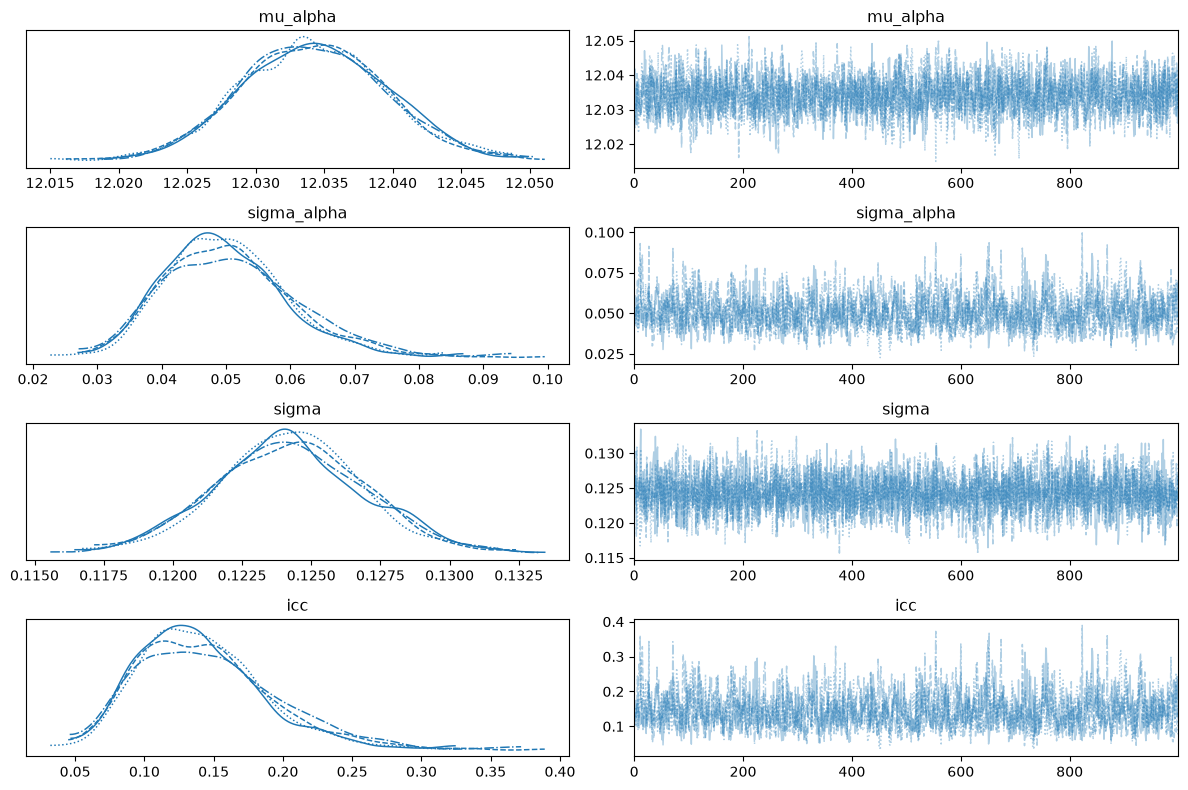

In [120]:
def get_mcmc_diagnostics(name, idata):
    return {
        'model': name,
        'max_rhat': float(az.rhat(idata).to_array().max()),
        'min_bulk_ess': float(az.ess(idata, method='bulk').to_array().min()),
        'min_tail_ess': float(az.ess(idata, method='tail').to_array().min()),
        'divergences': int(idata.sample_stats['diverging'].sum())
    }

mixed_summary = az.summary(
    mixed_fit, var_names=['mu_alpha', 'sigma_alpha', 'icc', 'sigma'],
    hdi_prob=0.90, round_to=4
)
display(mixed_summary)
mixed_summary.to_csv(results_path / 'mixed_effects_parameter_summary.csv')

all_diagnostics = pd.DataFrame([
    get_mcmc_diagnostics('Partial Pooling Mixed Model', mixed_fit),
    get_mcmc_diagnostics('No Pooling Model', nopool_fit)
])
display(all_diagnostics.round(3))
all_diagnostics.to_csv(results_path / 'mixed_effects_diagnostics.csv', index=False)

az.plot_trace(mixed_fit, var_names=['mu_alpha', 'sigma_alpha', 'sigma', 'icc'])
plt.tight_layout()
plt.savefig(results_path / 'mixed_effects_trace.png', dpi=140)
plt.show()

## Prior and posterior predictive checks

Before interpreting group effects, we verify that our weakly informative priors generate plausible log sale prices and that posterior predictive draws from the mixed effects model accurately replicate the observed training distribution.

Partial Pooling Mixed Model: replicated training statistics


,mean_log_price,sd_log_price
0.05,12.016,0.401
0.50,12.025,0.410
0.95,12.033,0.418


Observed training mean and SD: 12.025 0.409


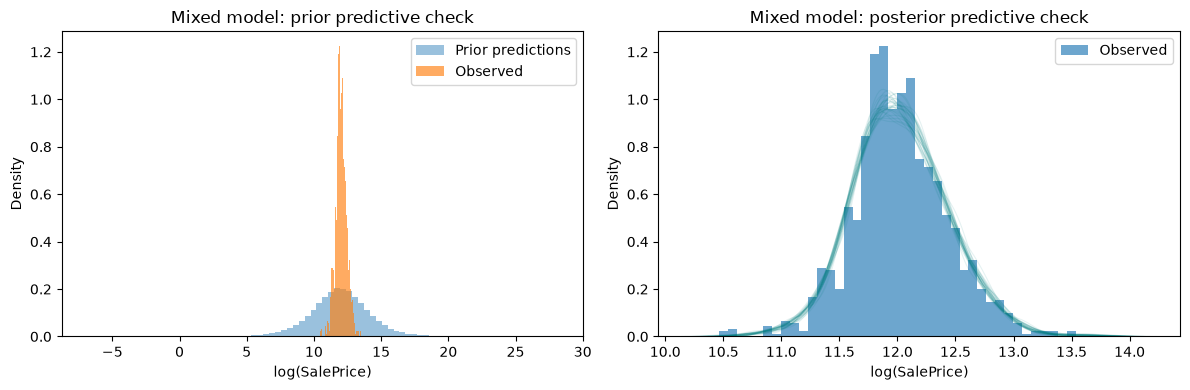

In [121]:
post = mixed_fit.posterior.stack(sample=('chain', 'draw'))
a_train = post['alpha'].values[nbhd_train_idx, :]
b_draws = post['beta'].values
s_draws = post['sigma'].values[None, :]
mu_train = a_train + (final_X_train @ b_draws)

rng = np.random.default_rng(6812)
y_train_rep = rng.normal(loc=mu_train, scale=s_draws)

rep_stats = pd.DataFrame({
    'mean_log_price': y_train_rep.mean(axis=0),
    'sd_log_price': y_train_rep.std(axis=0)
}).quantile([0.05, 0.50, 0.95])
print("Partial Pooling Mixed Model: replicated training statistics")
display(rep_stats.round(3))
print("Observed training mean and SD:", round(float(y_train.mean()), 3), round(float(y_train.std()), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

prior_vals = mixed_prior.prior_predictive['log_price_obs'].to_numpy().ravel()
axes[0].hist(prior_vals, bins=80, density=True, alpha=0.45, label='Prior predictions')
axes[0].hist(y_train, bins=40, density=True, alpha=0.65, label='Observed')
axes[0].set(title='Mixed model: prior predictive check', xlabel='log(SalePrice)', ylabel='Density')
axes[0].legend()

axes[1].hist(y_train, bins=40, density=True, alpha=0.65, label='Observed')
step = max(1, y_train_rep.shape[1] // 30)
for idx in range(0, y_train_rep.shape[1], step):
    sns.kdeplot(y_train_rep[:, idx], ax=axes[1], color='teal', alpha=0.10, linewidth=0.8)
axes[1].set(title='Mixed model: posterior predictive check', xlabel='log(SalePrice)', ylabel='Density')
axes[1].legend()

plt.tight_layout()
plt.savefig(results_path / 'mixed_effects_predictive_checks.png', dpi=140)
plt.show()

## Interpret the Intraclass Correlation Coefficient (ICC)

The Intraclass Correlation Coefficient quantifies the proportion of unexplained price variance directly attributable to neighborhood differences, statistically justifying our hierarchical approach.

In [122]:
icc_posterior = mixed_fit.posterior['icc'].values.flatten()
print(f"Posterior Mean ICC: {icc_posterior.mean():.3f}")
print(f"90% HDI ICC: {np.percentile(icc_posterior, [5, 95])}")

Posterior Mean ICC: 0.143
90% HDI ICC: [0.07771392 0.23320479]


## Visualize posterior neighborhood baseline prices (Caterpillar Plot)

To interpret the hierarchical structure and partial pooling shrinkage, we plot the posterior mean and 90% credible intervals for each neighborhood's baseline log sale price ($\alpha_j$) relative to the global intercept ($\mu_\alpha$).

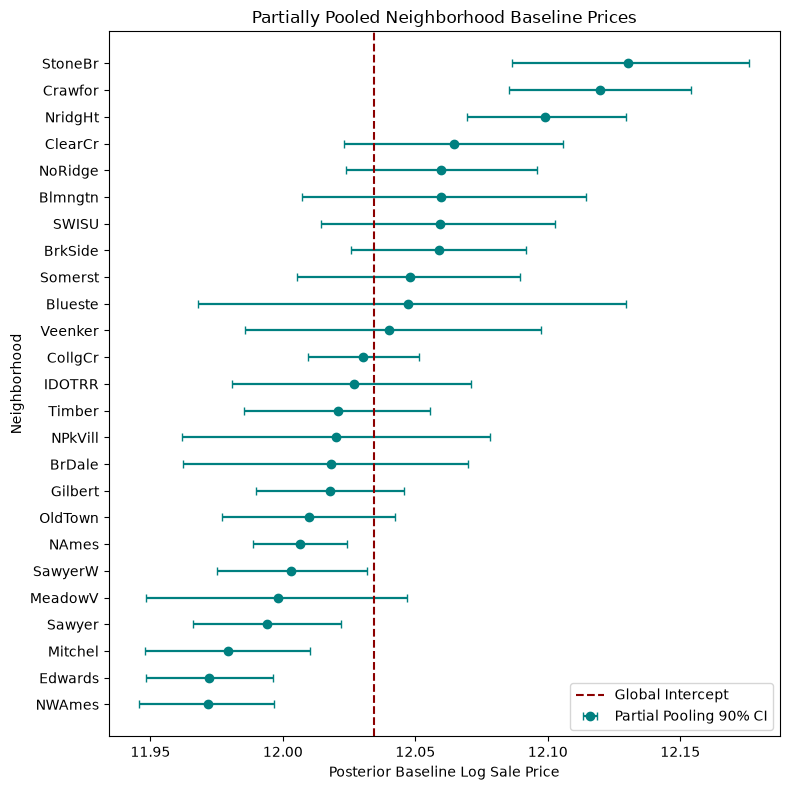

In [123]:
alpha_mixed_samples = mixed_fit.posterior['alpha'].stack(sample=('chain', 'draw')).values
mu_alpha_val = float(mixed_fit.posterior['mu_alpha'].mean().values)

caterpillar_df = pd.DataFrame({
    'Neighborhood': neighborhoods,
    'mixed_mean': alpha_mixed_samples.mean(axis=1),
    'mixed_low_90': np.percentile(alpha_mixed_samples, 5.0, axis=1),
    'mixed_high_90': np.percentile(alpha_mixed_samples, 95.0, axis=1)
}).sort_values('mixed_mean', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 8))
ax.errorbar(
    caterpillar_df['mixed_mean'], caterpillar_df['Neighborhood'],
    xerr=[caterpillar_df['mixed_mean'] - caterpillar_df['mixed_low_90'],
          caterpillar_df['mixed_high_90'] - caterpillar_df['mixed_mean']],
    fmt='o', color='teal', ecolor='teal', elinewidth=1.6, capsize=3, label='Partial Pooling 90% CI'
)
ax.axvline(mu_alpha_val, color='darkred', linestyle='--', linewidth=1.5, label='Global Intercept')
ax.set(
    title='Partially Pooled Neighborhood Baseline Prices',
    xlabel='Posterior Baseline Log Sale Price',
    ylabel='Neighborhood'
)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(results_path / 'mixed_effects_caterpillar.png', dpi=140)
plt.show()

## Evaluate held-out predictions against the 13-feature Bayesian benchmark

Using the exact scoring rules from the handoff:
- **Dollar point prediction:** $\hat{y}_i = \text{mean}\left(\exp(\mu_i + \sigma^2 / 2)\right)$ across posterior draws.
- **Log RMSE:** $\sqrt{\frac{1}{n}\sum (\text{LogSalePrice}_i - \ln(\hat{y}_i))^2}$.
- **90% Prediction Interval:** 5th and 95th percentiles of simulated posterior predictive dollar prices $\exp(y_i^{\text{rep}})$.

In [124]:
def evaluate_preds(idata, X_h, nbhd_h):
    post = idata.posterior.stack(sample=('chain', 'draw'))
    a_draws = post['alpha'].values[nbhd_h, :]
    b_draws = post['beta'].values
    s_draws = post['sigma'].values[None, :]
    
    mu_h = a_draws + (X_h @ b_draws)
    pred_mean = np.exp(mu_h + (s_draws ** 2) / 2.0).mean(axis=1)
    
    rng = np.random.default_rng(6810)
    sim_prices = np.exp(rng.normal(loc=mu_h, scale=s_draws))
    low_90 = np.percentile(sim_prices, 5.0, axis=1)
    high_90 = np.percentile(sim_prices, 95.0, axis=1)
    return pred_mean, low_90, high_90

mix_mean, mix_low, mix_high = evaluate_preds(mixed_fit, final_X_holdout, nbhd_hold_idx)
nopool_mean, nopool_low, nopool_high = evaluate_preds(nopool_fit, final_X_holdout, nbhd_hold_idx)

def get_scores(mean_p, low_p, high_p):
    return {
        'RMSE_dollars': np.sqrt(np.mean((actual_prices - mean_p) ** 2)),
        'MAE_dollars': np.mean(np.abs(actual_prices - mean_p)),
        'log_RMSE': np.sqrt(np.mean((y_holdout - np.log(mean_p)) ** 2)),
        'coverage_90_pct': 100.0 * np.mean((actual_prices >= low_p) & (actual_prices <= high_p)),
        'mean_interval_width_dollars': np.mean(high_p - low_p)
    }

results_table = pd.DataFrame([
    baseline_metrics.to_dict(),
    get_scores(nopool_mean, nopool_low, nopool_high),
    get_scores(mix_mean, mix_low, mix_high)
], index=['Complete Pooling Benchmark', 'No Pooling Model', 'Partial Pooling Mixed Model'])

display(results_table.round(3))

,RMSE_dollars,MAE_dollars,log_RMSE,coverage_90_pct,mean_interval_width_dollars
Complete Pooling Benchmark,21137.194,14547.295,0.117,93.814,75495.663
No Pooling Model,20035.657,14007.645,0.111,94.158,73281.180
Partial Pooling Mixed Model,19949.000,13842.193,0.111,94.158,72993.224


## Export mixed effects predictions and comparison summary

We save the held out dollar predictions, posterior predictive medians, and 90% prediction intervals alongside each home `Id` so all team models can be compared row by row in the final report.

In [125]:
def build_prediction_table(idata, X_h, nbhd_h, seed=6810):
    post = idata.posterior.stack(sample=('chain', 'draw'))
    a_draws = post['alpha'].values[nbhd_h, :]
    b_draws = post['beta'].values
    s_draws = post['sigma'].values[None, :]
    mu_h = a_draws + (X_h @ b_draws)
    pred_mean = np.exp(mu_h + (s_draws ** 2) / 2.0).mean(axis=1)
    rng = np.random.default_rng(seed)
    sim_prices = np.exp(rng.normal(loc=mu_h, scale=s_draws))
    low_90, pred_median, high_90 = np.percentile(sim_prices, [5.0, 50.0, 95.0], axis=1)
    return pd.DataFrame({
        'Id': holdout['Id'].to_numpy(),
        'actual_price': actual_prices.to_numpy(),
        'predicted_mean': pred_mean,
        'predicted_median': pred_median,
        'lower_90': low_90,
        'upper_90': high_90
    })

mixed_preds_df = build_prediction_table(mixed_fit, final_X_holdout, nbhd_hold_idx)
nopool_preds_df = build_prediction_table(nopool_fit, final_X_holdout, nbhd_hold_idx)

mixed_preds_df.to_csv(results_path / 'mixed_effects_holdout_predictions.csv', index=False)
nopool_preds_df.to_csv(results_path / 'nopool_holdout_predictions.csv', index=False)
results_table.to_csv(results_path / 'mixed_effects_model_comparison.csv')

print("Saved prediction tables and comparison summary to:", results_path)
display(mixed_preds_df.head().round(2))

Saved prediction tables and comparison summary to: /Users/abdirahmanali/Fall 2026/Bayesian/Kaggle-Housing-Prediction-dataset/analysis_results


,Id,actual_price,predicted_mean,predicted_median,lower_90,upper_90
0,546,229000,239906.74,237730.14,194711.20,293108.89
1,444,172500,194313.99,193456.76,157826.36,238429.99
2,1322,72500,81522.45,81137.09,65603.17,99989.19
3,287,159000,195047.73,194192.53,157413.31,237570.69
4,236,89500,89325.99,89084.40,71627.01,109786.89
